# Что происходит в нашей статье: от обычного FW до точной остановки

**Учебный спутник русской статьи от 17 октября 2026 года.**

Достаточно помнить, что Франк–Вульф выбирает вершину по градиенту и
делает шаг в её сторону. Всё остальное введём здесь с нуля.
Код читать необязательно: главное — текст, картинки и подписи.
В сохранённом ноутбуке картинки уже построены. Чтобы менять примеры,
выбирайте **Run All / Выполнить всё** в Jupyter или VS Code.

В начале каждого раздела есть блок **«Обозначения под рукой»**:
в нём повторяются нужные именно здесь переменные. Индекс $k$ означает
номер текущей точки; запись без индекса, например $U$ вместо $U_k$,
обычно означает ту же величину в одной рассматриваемой точке.
В основной задаче сокращение $f^*$ означает минимум на $Q$, то есть
$f_Q^*$; отдельные глобальные утверждения в приложении оговорены явно.

**Главная мысль статьи:** мы изучаем известный алгоритм, который сам
подбирает длину шага. Если изгиб функции уменьшается вместе с ошибкой,
можно точнее оценить, сколько работы нужно **до проверяемой остановки**.
В особом случае на многограннике AFW за конечное число шагов попадает
точно в множество минимумов.

Сначала пройдите пункты 1–8. Пункты 9–14 объясняют основные теоремы;
15–18 — эксперименты, приложения и границы научных выводов.

| Путь | Что станет понятно |
| --- | --- |
| 1–3 | Задача, градиент, вершина и один шаг FW |
| 4–5 | Как узнать, что пора остановиться, не зная минимума |
| 6–8 | Кривизна, backtracking и стоимость проб |
| 9–10 | Откуда берутся логарифм и цена начальной настройки |
| 11–14 | Удаление атомов, огибающая зазора и точный финиш |
| 15–18 | Что показывают данные и что именно утверждает статья |

[Русская статья, PDF](../Paper/article_ru.pdf) ·
[Исходники](../Paper/article_ru.tex) ·
[Сравнение с литературой](../Work/literature_review_2026_10_17.md)

Учебные примеры ниже не являются новыми экспериментами статьи.
Настоящие сохранённые результаты будут отдельно в пункте 15.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
import csv
import math
from fractions import Fraction
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.grid': True, 'grid.alpha': .18,
    'figure.figsize': (11, 4.2), 'figure.dpi': 115,
    'savefig.facecolor': 'white', 'axes.facecolor': '#fafbfe',
})
BLUE, ORANGE, GREEN, RED = '#2563eb', '#e88920', '#16866b', '#c44455'

def table(headers, rows):
    # Cells here are internal strings, not untrusted HTML.
    head = ''.join(f'<th style="padding:7px;text-align:left">{x}</th>' for x in headers)
    body = ''.join('<tr>' + ''.join(f'<td style="padding:6px 9px">{x}</td>' for x in row)
                   + '</tr>' for row in rows)
    display(HTML('<table style="border-collapse:collapse;font-size:14px">'
                 f'<thead style="background:#e8eefb"><tr>{head}</tr></thead>'
                 f'<tbody>{body}</tbody></table>'))

def positive(y):
    # Only a display floor for logarithmic axes, never a stopping rule.
    return np.maximum(np.asarray(y, dtype=float), 1e-16)

def arr(trace, key):
    return np.asarray([r[key] for r in trace])

print('Готово. Нужны только NumPy, Matplotlib и IPython; картинки строятся локально.')

Готово. Нужны только NumPy, Matplotlib и IPython; картинки строятся локально.


## 1. Что мы вообще решаем

> **Обозначения под рукой.** $x$ — точка, которую выбираем; $f(x)$ — её цена.
> $Q$ — разрешённая область; $x^*$ — любая лучшая точка в ней.
> $f_Q^*$ — наименьшая цена на $Q$; звёздочка обозначает оптимальность.

Пишем $\min_{x\in Q} f(x)$. Здесь:

- $x$ — набор чисел, который разрешено менять;
- $f(x)$ — цена, ошибка или потери: чем меньше, тем лучше;
- $Q$ — множество разрешённых значений $x$;
- $x^*$ — любая наилучшая разрешённая точка;
- $f_Q^*=f(x^*)$ — наименьшая цена **с учётом ограничения**.

Для картинки возьмём две координаты $x=(x_1,x_2)$ и треугольник
$Q=\{x_1\ge0,\ x_2\ge0,\ x_1+x_2\le1\}$.
Наша цена:

$$f(x)=\frac12\big[(x_1-0.2)^2+4(x_2-0.6)^2\big].$$

Это выпуклая «чаша». Выпуклость означает: график между двумя точками
не поднимается выше соединяющей их прямой. Из-за этого локальные
касательные дают глобальные нижние оценки. В этой учебной задаче
минимум известен: $x^*=(0.2,0.6)$, $f_Q^*=0$.
Позже мы используем это знание **для проверки рисунков**, а алгоритму
оптимум передавать не будем.

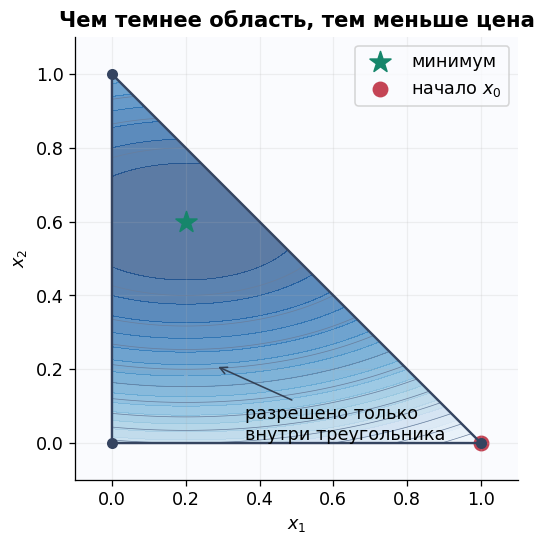

In [2]:
V = np.array([[0., 0.], [1., 0.], [0., 1.]])
target = np.array([.2, .6])
def bowl(x):
    z = np.asarray(x) - target
    return .5 * (z[..., 0]**2 + 4*z[..., 1]**2)
def bowl_grad(x):
    return (np.asarray(x) - target) * np.array([1., 4.])

def draw_triangle(ax, objective=bowl, mark_opt=True):
    xx, yy = np.meshgrid(np.linspace(0, 1, 180), np.linspace(0, 1, 180))
    zz = objective(np.stack([xx, yy], axis=-1))
    zz = np.where(xx+yy <= 1.000001, zz, np.nan)
    ax.contourf(xx, yy, zz, levels=22, cmap='Blues_r', alpha=.65)
    ax.contour(xx, yy, zz, levels=12, colors='#687e9d', linewidths=.45)
    ax.plot(*V[[0,1,2,0]].T, color='#354460', lw=1.5)
    ax.scatter(*V.T, s=35, color='#354460', zorder=4)
    if mark_opt:
        ax.scatter(*target, marker='*', s=190, color=GREEN, zorder=6, label='минимум')
    ax.set(xlim=(-.1,1.1), ylim=(-.1,1.1), xlabel='$x_1$', ylabel='$x_2$')
    ax.set_aspect('equal')

fig, ax = plt.subplots(figsize=(6,5))
draw_triangle(ax)
ax.scatter(1,0,s=80,color=RED,label='начало $x_0$')
ax.annotate('разрешено только\nвнутри треугольника', (.28,.21), (.36,.01),
            arrowprops={'arrowstyle':'->','color':'#334155'})
ax.set_title('Чем темнее область, тем меньше цена')
ax.legend(loc='upper right')
plt.show()

**Как читать картинку:** линии — точки с одинаковой ценой.
Зелёная звезда — дно чаши. Красная точка — откуда начинаем.
Треугольник ограничивает движения; выходить за его стороны нельзя.

Ограниченный минимум может лежать на границе. Тогда градиент в нём
**не обязан быть нулём**: например, у $f(x)=x$ на $[0,1]$ минимум
в нуле, хотя производная везде равна единице.

## 2. Вспоминаем один шаг Франка–Вульфа

> **Обозначения под рукой.** $x_k$ — текущая точка на шаге $k$; $Q$ — разрешённая область.
> $\nabla f(x_k)$ — градиент, направление локального роста цены.
> $s_k$ — точка, выбранная линейным оракулом LMO; $d_k=s_k-x_k$ — направление к ней.
> $\alpha_k$ — доля шага; $x_{k+1}$ — точка после обновления.

Градиент $\nabla f(x)$ показывает направление самого быстрого роста
в бесконечно малой окрестности. Скалярное произведение
$\langle a,b\rangle=\sum_j a_jb_j$ измеряет согласованность направлений.

FW заменяет чашу её касательной плоскостью и спрашивает:
**«В какой разрешённой точке эта линейная модель самая низкая?»**

$$s_k\in\arg\min_{v\in Q}\langle\nabla f(x_k),v\rangle.$$

Это LMO — *linear minimization oracle*, оракул линейной минимизации.
«Оракул» здесь просто подпрограмма, решающая эту подзадачу.
На нашем треугольнике достаточно сравнить три вершины.
На большом многограннике вершины не обязательно перечислять:
для некоторых областей есть гораздо более дешёвое правило.

Затем $d_k=s_k-x_k$, и

$$x_{k+1}=x_k+\alpha_k d_k=(1-\alpha_k)x_k+\alpha_k s_k,
\qquad 0\le\alpha_k\le1.$$

Это движение по отрезку к выбранной вершине. Выпуклость $Q$
гарантирует, что весь отрезок разрешён. FW-вершина — **не обещание,
что минимум именно там**; это ответ только на линейную подзадачу.

вершина,градиент · вершина,выбрана?
"(np.float64(0.0), np.float64(0.0))",0.00,
"(np.float64(1.0), np.float64(0.0))",0.80,
"(np.float64(0.0), np.float64(1.0))",-2.40,да


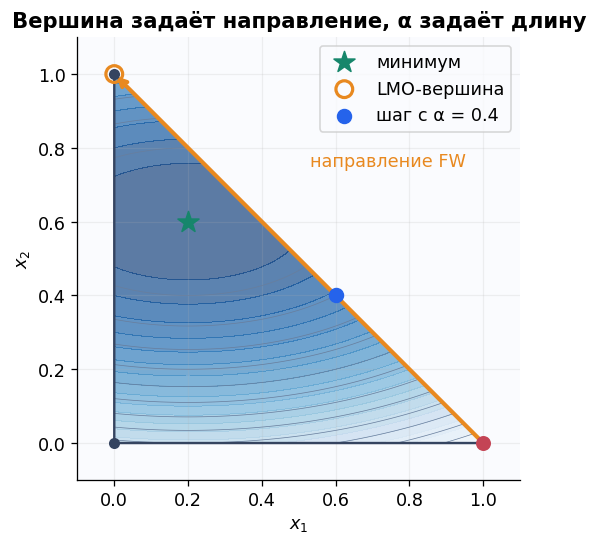

In [3]:
x_demo = np.array([1.,0.])
grad_demo = bowl_grad(x_demo)
scores = V @ grad_demo
s_demo = V[np.argmin(scores)]
d_demo = s_demo-x_demo
G_demo = -grad_demo@d_demo
table(['вершина', 'градиент · вершина', 'выбрана?'],
      [(str(tuple(v)), f'{score:.2f}', 'да' if np.array_equal(v,s_demo) else '')
       for v,score in zip(V,scores)])
fig, ax = plt.subplots(figsize=(6,5))
draw_triangle(ax)
ax.scatter(*x_demo, s=70, color=RED, zorder=6)
ax.annotate('', s_demo, x_demo, arrowprops={'arrowstyle':'->','color':ORANGE,'lw':2.6})
ax.annotate('направление FW', (.51,.49), (.53,.75), color=ORANGE)
ax.scatter(*s_demo,s=110,facecolors='none',edgecolors=ORANGE,lw=2,zorder=6,label='LMO-вершина')
x_next = x_demo+.4*d_demo
ax.scatter(*x_next,s=75,color=BLUE,zorder=7,label='шаг с α = 0.4')
ax.set_title('Вершина задаёт направление, α задаёт длину')
ax.legend(loc='upper right')
plt.show()

## 3. Маленький решатель для следующих картинок

> **Обозначения под рукой.** $x_0$ — начальная точка; $x_k$ — текущая точка.
> $M>0$ — начальная настройка кривизны; $\varepsilon$ (`eps`) — требуемая точность.
> $\lambda_v$ — вес вершины $v$ в смеси; `weights0` — начальные веса.
> $f_Q^*$ — неизвестный минимум цены; $H_0,H_1$ — константы ограничения кривизны, подробно в пункте 6.

Ниже спрятан учебный код FW и AFW. Он использует функции, градиенты
и конечный список вершин. Он **не получает** $x^*, f_Q^*,H_0,H_1$.
Правило шага — ровно halving/doubling из основной статьи.
В AFW код дополнительно хранит веса вершин; это разберём в пункте 11.

Код можно раскрыть, но для понимания статьи это необязательно.
Во всех учебных запусках считаются обращения к функции, градиенту
и LMO. Проверка остановки в последней точке тоже оплачивается.

In [4]:
def run_fw(f, grad, vertices, weights0, *, M=1., eps=1e-6,
           max_steps=300, away=False):
    vertices = np.asarray(vertices, dtype=float)
    w = np.asarray(weights0, dtype=float).copy()
    if M <= 0 or eps < 0 or np.min(w) < 0 or not np.isclose(w.sum(), 1):
        raise ValueError('Проверьте M, допуск и начальные веса')
    counts = {'nf':0, 'ng':0, 'nlmo':0, 'active_scores':0}
    def value(z):
        counts['nf'] += 1
        return float(f(z))
    x = w@vertices
    fx = value(x)
    lower, L_previous = -np.inf, float(M)
    trace = []
    for k in range(max_steps+1):
        g = np.asarray(grad(x), dtype=float)
        counts['ng'] += 1
        scores = vertices@g
        counts['nlmo'] += 1
        s_index = int(np.argmin(scores))
        d_fw = vertices[s_index]-x
        G = float(-g@d_fw)
        assert G >= -1e-10, 'LMO должен давать неотрицательный зазор'
        G = max(0., G)
        lower = max(lower, fx-G)
        U = max(0., fx-lower)
        row = dict(k=k, x=x.copy(), weights=w.copy(), f=fx, G=G,
                   lower=lower, U=U, **counts)
        trace.append(row)
        if U <= eps or k == max_steps:
            break
        kind, chosen, direction, gap, cap = 'FW', s_index, d_fw, G, 1.
        active = np.flatnonzero(w>0)
        if away and len(active)>1:
            counts['active_scores'] += len(active)
            v_index = int(active[np.argmax(scores[active])])
            away_gap = float(g@(vertices[v_index]-x))
            if away_gap > G:
                kind, chosen = 'away', v_index
                direction, gap = x-vertices[v_index], away_gap
                cap = w[v_index]/(1-w[v_index])
        q2 = float(direction@direction)
        if gap <= 0 or q2 <= 0:
            raise ArithmeticError('Нет направления спуска при ненулевом сертификате')
        L, trials = L_previous/2, []
        for _ in range(100):
            alpha = min(cap, gap/(L*q2))
            w_trial = (1-alpha)*w if kind=='FW' else (1+alpha)*w
            w_trial[chosen] += alpha if kind=='FW' else -alpha
            drop = kind=='away' and alpha==cap
            if drop:
                w_trial[chosen] = 0.  # only the capped combinatorial drop
            if kind=='FW' and alpha==1:
                w_trial[:] = 0.; w_trial[chosen] = 1.
            assert w_trial.min() >= -1e-13
            w_trial /= w_trial.sum()
            trial_x = w_trial@vertices
            trial_f = value(trial_x)
            rhs = fx-alpha*gap+.5*L*alpha**2*q2
            accepted = trial_f <= rhs
            trials.append(dict(L=L, alpha=alpha, f=trial_f, rhs=rhs,
                               accepted=bool(accepted)))
            if accepted:
                break
            L *= 2
        else:
            raise RuntimeError('Слишком много проб')
        row.update(kind=kind, alpha=alpha, cap=cap, L=L, gap=gap,
                   direction=direction.copy(), trials=trials, drop=drop,
                   nf_after_step=counts['nf'])
        assert trial_f <= fx+1e-12
        w, x, fx, L_previous = w_trial, trial_x, trial_f, L
    return trace

triangle_run = run_fw(bowl, bowl_grad, V, [0,1,0], M=1., eps=1e-5, max_steps=350)
assert all(r['f'] <= r['U']+1e-11 <= r['G']+1e-10 for r in triangle_run)
assert all(np.all(r['weights']>=0) and np.isclose(r['weights'].sum(),1)
           for r in triangle_run)
print(f'В учебном запуске: {len(triangle_run)-1} обновлений; '
      f'последний сертификат U = {triangle_run[-1]["U"]:.3g}.')

В учебном запуске: 120 обновлений; последний сертификат U = 9.05e-06.


## 4. Когда останавливаться, если минимум неизвестен?

> **Обозначения под рукой.** $f(x_k)$ — цена сейчас; $f_Q^*$ — неизвестная лучшая цена на $Q$.
> $\delta_k=f(x_k)-f_Q^*$ — истинная ошибка по значению функции.
> $s_k$ — ответ LMO; $G_k=\langle\nabla f(x_k),x_k-s_k\rangle$ — вычислимый FW-зазор.
> $y\in Q$ — любая разрешённая точка, с которой сравниваем текущую.

Истинная ошибка — $\delta_k=f(x_k)-f_Q^*$.
Проблема: $f_Q^*$ нам обычно неизвестно. Смотреть, что «значение
почти не меняется», недостаточно: маленький шаг тоже почти ничего
не меняет, даже далеко от решения.

У FW есть вычислимый зазор:

$$G_k=\langle\nabla f(x_k),x_k-s_k\rangle.$$

Это **предсказанное линейной моделью** уменьшение при полном шаге
к LMO-вершине. Это не обязательно реальное уменьшение функции.
Из выпуклости:

$$f(y)\ge f(x_k)+\langle\nabla f(x_k),y-x_k\rangle.$$

Минимизируем правую часть по разрешённым $y$ с помощью LMO:

$$f_Q^*\ge f(x_k)-G_k.$$

Значит, $0\le\delta_k\le G_k$. Если $G_k=10^{-5}$, мы точно
не хуже оптимума больше чем на $10^{-5}$ — при точных оракулах
и арифметике. Оптимум для этой проверки не требуется!

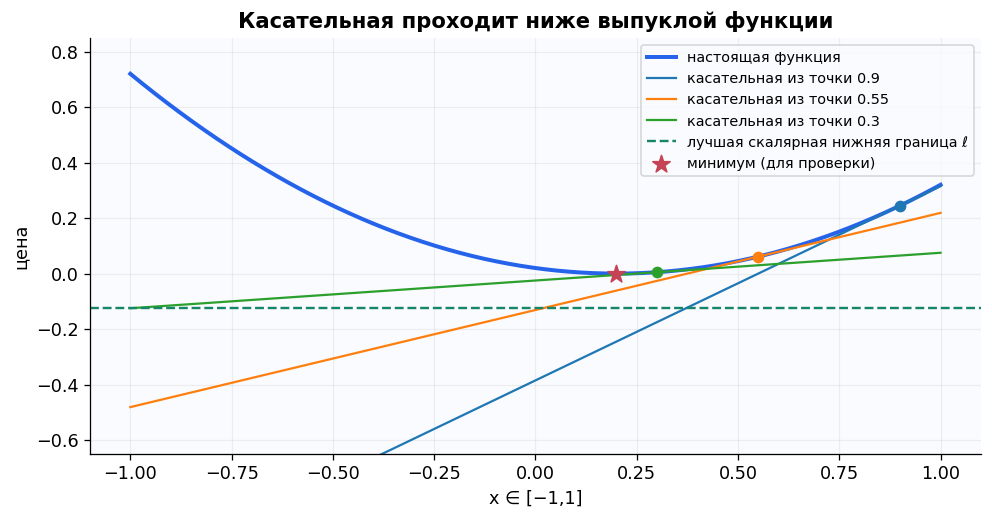

In [5]:
z = np.linspace(-1,1,400)
f1 = lambda z: .5*(z-.2)**2
observations = [.9,.55,.3]
fig, ax = plt.subplots(figsize=(10,4.7))
ax.plot(z, f1(z), color=BLUE,lw=2.5,label='настоящая функция')
lower_bounds = []
for i,point in enumerate(observations):
    slope = point-.2
    line = f1(point)+slope*(z-point)
    lb = f1(point)-slope*(point+1)
    lower_bounds.append(lb)
    ax.plot(z,line,lw=1.4,label=f'касательная из точки {point}')
    ax.scatter(point,f1(point),s=40,zorder=5)
ax.axhline(max(lower_bounds),color=GREEN,ls='--',label='лучшая скалярная нижняя граница ℓ')
ax.scatter(.2,0,marker='*',s=130,color=RED,zorder=5,label='минимум (для проверки)')
ax.set(xlabel='x ∈ [−1,1]',ylabel='цена',ylim=(-.65,.85),
       title='Касательная проходит ниже выпуклой функции')
ax.legend(fontsize=9,loc='upper right')
plt.show()

## 5. Зачем хранить прошлое: сертификат U

> **Обозначения под рукой.** $k$ — текущий номер; $i\le k$ — номер уже посещённой точки.
> $G_i$ — FW-зазор в точке $x_i$; $f(x_i)-G_i$ — нижняя граница неизвестного минимума $f_Q^*$.
> $\ell_k$ — наибольшая из сохранённых нижних границ; $U_k=f(x_k)-\ell_k$ — сертификат ошибки.
> $\delta_k=f(x_k)-f_Q^*$ — истинная ошибка; $\varepsilon$ — требуемая точность. Всегда $\delta_k\le U_k\le G_k$.

Каждая уже посещённая точка дала нижнюю границу $f(x_i)-G_i$.
Можно бесплатно запомнить лучшую:

$$\ell_k=\max_{0\le i\le k}\{f(x_i)-G_i\},\qquad
U_k=f(x_k)-\ell_k.$$

Получается важная цепочка:

$$\boxed{0\le\underbrace{\delta_k}_{\text{не знаем}}
\le\underbrace{U_k}_{\text{считаем с памятью}}
\le\underbrace{G_k}_{\text{считаем сейчас}}.}$$

Остановка статьи: **$U_k\le\varepsilon$**, где $\varepsilon$ —
желаемая точность по значению функции, например $10^{-5}$.
При спуске $f(x_k)$ не растёт, $\ell_k$ не убывает, поэтому $U_k$
не растёт. Сам $G_k$ может колебаться.

**Терминальная точка** — та, где выполнена проверка остановки.
При $\varepsilon>0$ это не обязательно точный минимум.
«Исходная точка шага» в статье означает текущую $x_k$, а не
обязательно единственную начальную $x_0$.

Скалярный сертификат с памятью известен до нашей статьи.
Здесь исследуется стоимость достижения его порога при специальной
модели кривизны.

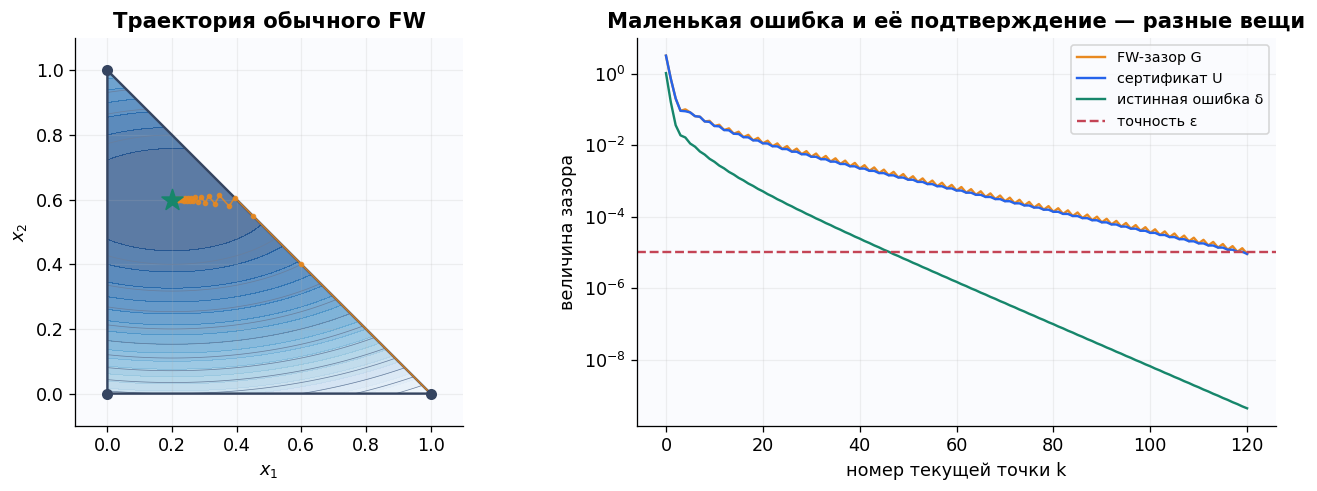

k,f(x) = δ (знаем лишь в примере),G,ℓ,U
0,1.04,3.2,-2.16,3.2
1,0.16,0.72,-0.56,0.72
2,0.03625,0.2025,-0.16625,0.2025
3,0.018848,0.091445,-0.072598,0.091445
4,0.016402,0.10054,-0.072598,0.089
5,0.011108,0.082553,-0.071444,0.082553


In [6]:
fig, axes = plt.subplots(1,2,figsize=(12,4.4))
path = arr(triangle_run,'x')
draw_triangle(axes[0])
axes[0].plot(*path.T,'o-',color=ORANGE,markersize=2.5,lw=1,alpha=.85)
axes[0].set_title('Траектория обычного FW')
for key,label,color in [('G','FW-зазор G',ORANGE),('U','сертификат U',BLUE),
                        ('f','истинная ошибка δ',GREEN)]:
    axes[1].semilogy(arr(triangle_run,'k'),positive(arr(triangle_run,key)),
                     color=color,label=label,lw=1.5)
axes[1].axhline(1e-5,color=RED,ls='--',label='точность ε')
axes[1].set(xlabel='номер текущей точки k',ylabel='величина зазора',
            title='Маленькая ошибка и её подтверждение — разные вещи')
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
table(['k','f(x) = δ (знаем лишь в примере)','G','ℓ','U'],
      [(r['k'], f"{r['f']:.5g}", f"{r['G']:.5g}",f"{r['lower']:.5g}",f"{r['U']:.5g}")
       for r in triangle_run[:6]])

**Что видно:** зелёная линия всегда ниже синей, синяя — ниже оранжевой.
Приблизиться к минимуму и доказать это по доступной информации —
две разные задачи. Если в конце этой учебной траектории допуск ещё
не достигнут, это означает только достижение заданного лимита шагов.
Не нужно называть такой запуск сошедшимся.

**Проверьте себя:** если $U=0.001$, можно ли утверждать, что
$\delta=0.001$? Нет: известно лишь $\delta\le0.001$.

## 6. Главное предположение: изгиб может уменьшаться вместе с ошибкой

> **Обозначения под рукой.** $\delta(x)=f(x)-f_Q^*$ — ошибка цены относительно минимума на $Q$.
> $\nabla f$ — градиент; $\nabla^2f$ — гессиан, матрица вторых производных.
> $H_0$ — базовая разрешённая кривизна; $H_1$ — коэффициент её зависимости от ошибки.
> $L_Q$ — одна глобальная граница кривизны для всего $Q$; $R$ — половина длины отрезка $[-R,R]$ в примере.

В одном измерении производная $f'$ — наклон, вторая производная
$f''$ — изменение наклона, то есть изгиб. Для нескольких координат
вторые производные собираются в матрицу $\nabla^2 f$ — **гессиан**.
Его норма $\|\nabla^2 f\|_2$ — наибольший изгиб по направлениям.
Здесь $\|x\|$ без индекса — евклидова длина.

Обычная глобальная гладкость: $\|\nabla^2 f(x)\|_2\le L_Q$ всюду
на $Q$. Это как один скоростной лимит для всей дороги, выбранный
по самому крутому повороту.

В статье предполагается более информативная связь:

$$\boxed{\|\nabla^2 f(x)\|_2\le H_0+H_1\underbrace{(f(x)-f_Q^*)}_{\delta(x)},
\quad x\in Q.}$$

- $H_0\ge0$ — базовая разрешённая кривизна, остающаяся у минимума;
- $H_1\ge0$ — сколько дополнительной кривизны допускает ошибка;
- $H_1=0$ возвращает обычную ограниченную кривизну;
- $H_0=0$ — особый случай: у оптимума гессиан обязан стать нулём.

Это **верхнее ограничение**, а не равенство и не утверждение, что
каждая функция именно так изгибается. Пару $H_0,H_1$ часто можно
выбрать многими способами. Условие нужно доказать, а не подогнать
по нескольким точкам. Само семейство предположений известно ранее.

Пример: $f(x)=\cosh x-1$, где $\cosh x=(e^x+e^{-x})/2$.
На $[-R,R]$ минимум равен нулю, а
$f''(x)=\cosh x=1+f(x)$. Подходят $H_0=H_1=1$.
Глобальная граница при этом $L_Q=\cosh R$.

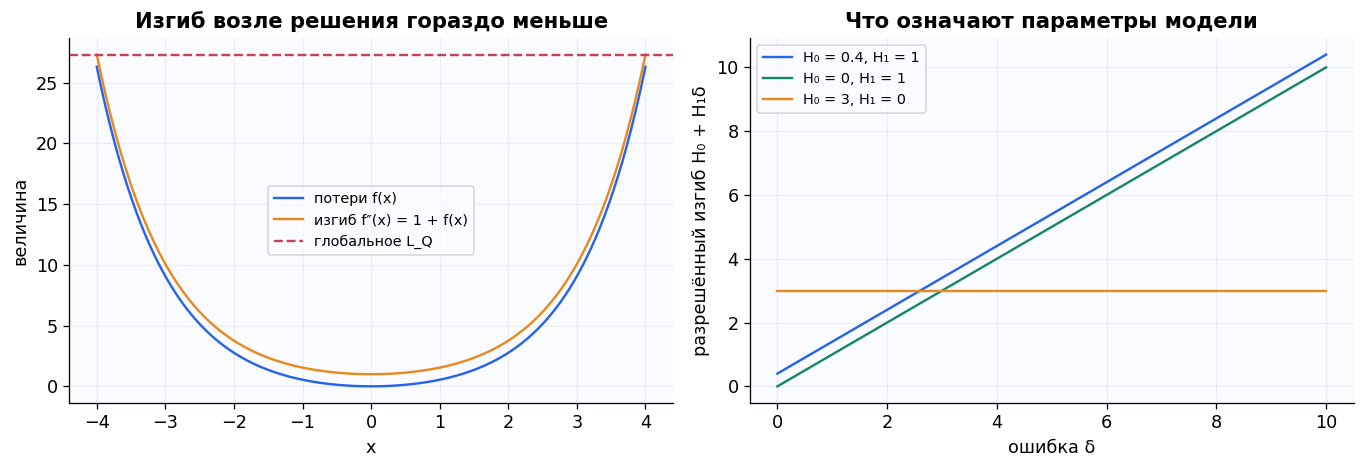

In [7]:
R = 4.
z = np.linspace(-R,R,500)
cosh_f = lambda x: np.cosh(np.asarray(x)[...,0])-1
cosh_grad = lambda x: np.sinh(x)
fig, axes = plt.subplots(1,2,figsize=(12,4.2))
axes[0].plot(z,np.cosh(z)-1,label='потери f(x)',color=BLUE)
axes[0].plot(z,np.cosh(z),label='изгиб f″(x) = 1 + f(x)',color=ORANGE)
axes[0].axhline(np.cosh(R),ls='--',color=RED,label='глобальное L_Q')
axes[0].set(xlabel='x',ylabel='величина',title='Изгиб возле решения гораздо меньше')
axes[0].legend(fontsize=9)
errors = np.linspace(0,10,200)
axes[1].plot(errors,.4+errors,color=BLUE,label='H₀ = 0.4, H₁ = 1')
axes[1].plot(errors,errors,color=GREEN,label='H₀ = 0, H₁ = 1')
axes[1].plot(errors,np.full_like(errors,3.),color=ORANGE,label='H₀ = 3, H₁ = 0')
axes[1].set(xlabel='ошибка δ',ylabel='разрешённый изгиб H₀ + H₁δ',
            title='Что означают параметры модели')
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

На правой картинке показаны **границы класса**, а не измеренная
кривизна конкретных траекторий. Синяя и зелёная границы уменьшаются
при движении по горизонтальной оси к нулю. Оранжевая не меняется.

На компакте у гладкой функции есть и конечная глобальная граница.
Смысл статьи не в её отсутствии, а в том, чтобы не терять информацию
о более мягком поведении ближе к решению.

## 7. Backtracking: как выбрать шаг, не зная H₀ и H₁

> **Обозначения под рукой.** $x$ — текущая точка; $s$ — ответ LMO; $d=s-x$ — направление шага.
> $G=-\langle\nabla f(x),d\rangle$ — FW-зазор; $\|d\|$ — длина направления.
> $\alpha$ — доля шага; $L$ — пробная оценка кривизны; $M=L_{-1}$ — её начальная настройка.
> $m_L(\alpha)$ — квадратичная модель цены после шага; $H_0,H_1$ — константы теории, не вход этого поиска.

Пусть направление $d=s-x$, зазор $G=-\langle\nabla f(x),d\rangle$.
Берём рабочую оценку кривизны $L>0$ и квадратичную модель:

$$m_L(\alpha)=f(x)-\alpha G+\frac12 L\alpha^2\|d\|^2.$$

Её минимум на отрезке $0\le\alpha\le1$ достигается при

$$\alpha=\min\left\{1,\frac{G}{L\|d\|^2}\right\}.$$

Дальше проверяем **настоящее** значение в пробной точке:

$$f(x+\alpha d)\le m_L(\alpha).$$

Если не получилось, удваиваем $L$ и пробуем заново. Если получилось,
принимаем точку. На следующей итерации начинаем с **половины**
предыдущего принятого $L$: вдруг функция стала менее изогнутой.
Начальное сохранённое значение обозначается $M=L_{-1}>0$.

Меньшее $L$ предлагает более смелый шаг; слишком маленькое $L$
может не пройти проверку. Слишком большое $L$ даёт осторожный шаг.
Принятый $L$ — рабочая оценка для одной пробы: он не обязан быть
глобальной верхней границей гессиана.

Ни оптимум, ни $H_0,H_1$ алгоритму здесь не нужны.

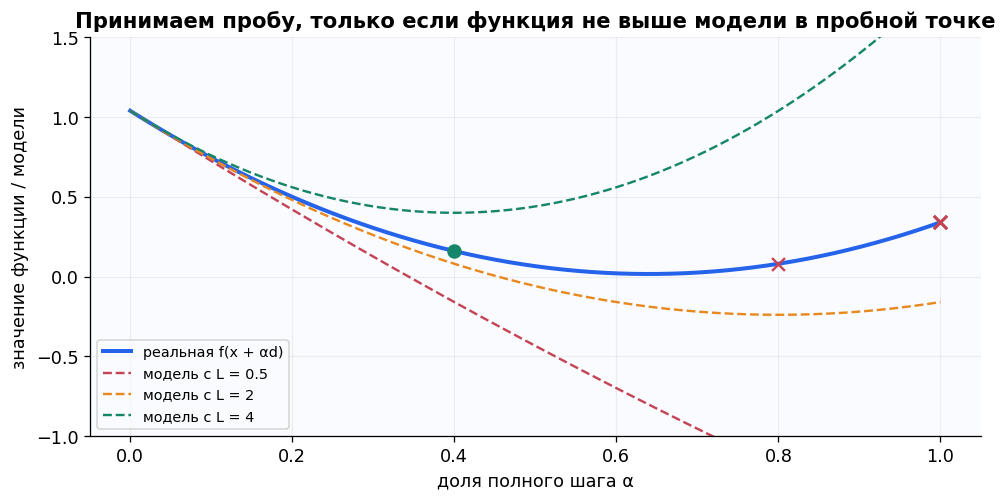

L,предложенный α,реальная f,модель m_L,решение
0.0625,1,0.34,-2.098,отклонить
0.125,1,0.34,-2.035,отклонить
0.25,1,0.34,-1.91,отклонить
0.5,1,0.34,-1.66,отклонить
1,1,0.34,-1.16,отклонить
2,0.8,0.08,-0.24,отклонить
4,0.4,0.16,0.4,принять


In [8]:
first_step = run_fw(bowl,bowl_grad,V,[0,1,0],M=.125,eps=0,max_steps=1)[0]
trials = first_step['trials']
alpha_grid = np.linspace(0,1,300)
actual = bowl(x_demo+alpha_grid[:,None]*d_demo)
fig, ax = plt.subplots(figsize=(10,4.5))
ax.plot(alpha_grid,actual,lw=2.5,color=BLUE,label='реальная f(x + αd)')
for L,color in [(.5,RED),(2.,ORANGE),(4.,GREEN)]:
    model = bowl(x_demo)-alpha_grid*G_demo+.5*L*alpha_grid**2*(d_demo@d_demo)
    ax.plot(alpha_grid,model,ls='--',color=color,label=f'модель с L = {L:g}')
for trial in trials:
    ax.scatter(trial['alpha'],trial['f'],color=GREEN if trial['accepted'] else RED,
               marker='o' if trial['accepted'] else 'x',s=65,zorder=5)
ax.set(xlabel='доля полного шага α',ylabel='значение функции / модели',ylim=(-1,1.5),
       title='Принимаем пробу, только если функция не выше модели в пробной точке')
ax.legend(fontsize=9)
plt.show()
table(['L','предложенный α','реальная f','модель m_L','решение'],
      [(f"{r['L']:.4g}",f"{r['alpha']:.3g}",f"{r['f']:.4g}",f"{r['rhs']:.4g}",
        'принять' if r['accepted'] else 'отклонить') for r in trials])

Крестики могут совпадать: несколько разных $L$ предложили один и тот
же полный шаг $\alpha=1$. Таблица всё равно показывает каждую пробу.
Принимаемая проверка нужна лишь в предложенной точке, не на всём графике.

**Почему спуск гарантирован:** по выбору $\alpha$,
$L\alpha\|d\|^2\le G$. Значит, принятое уменьшение не меньше
$\alpha G/2$. Проверка гарантирует положительное продвижение.
Условие статьи доказывает, что достаточно большое $L$ обязательно
пройдёт проверку, поэтому поиск не зависнет в точной арифметике.

## 8. За что платим: шаг не равен одному вычислению функции

> **Обозначения под рукой.** $N$ — число принятых обновлений; $N_f$ — число всех вызовов функции.
> $k$ — номер обновления; $r_k$ — число отклонённых проб на нём.
> $L_k$ — принятая оценка кривизны; $L_{k-1}$ — унаследованная; $M=L_{-1}$ — начальная.
> $\log_2$ — логарифм по основанию 2: число удвоений или делений пополам.

В нашей схеме одна новая текущая точка требует градиент и LMO.
Но до её принятия можно несколько раз вызвать функцию.
Отказ от пробы тоже стоит вычисления.

Если принято $N$ обновлений, есть $N+1$ текущих точек, включая
финальную проверку. Отсюда $N+1$ градиентов и полных LMO.
Начальное значение функции оплачивается один раз, принятое значение
сохраняется и повторно не вычисляется.

Если на шаге $k$ было $r_k$ отказов, то
$L_k=2^{r_k-1}L_{k-1}$. Сложение логарифмов даёт точное тождество:

$$N_f=1+\sum_{k=0}^{N-1}(r_k+1)
=1+2N+\log_2\frac{L_{N-1}}M,\qquad N\ge1.$$

Именно поэтому можно учитывать все отказы, не умножая грубо число
шагов на максимальное число проб. Это известный механизм подсчёта;
статья применяет его вместе со своим анализом остановки.

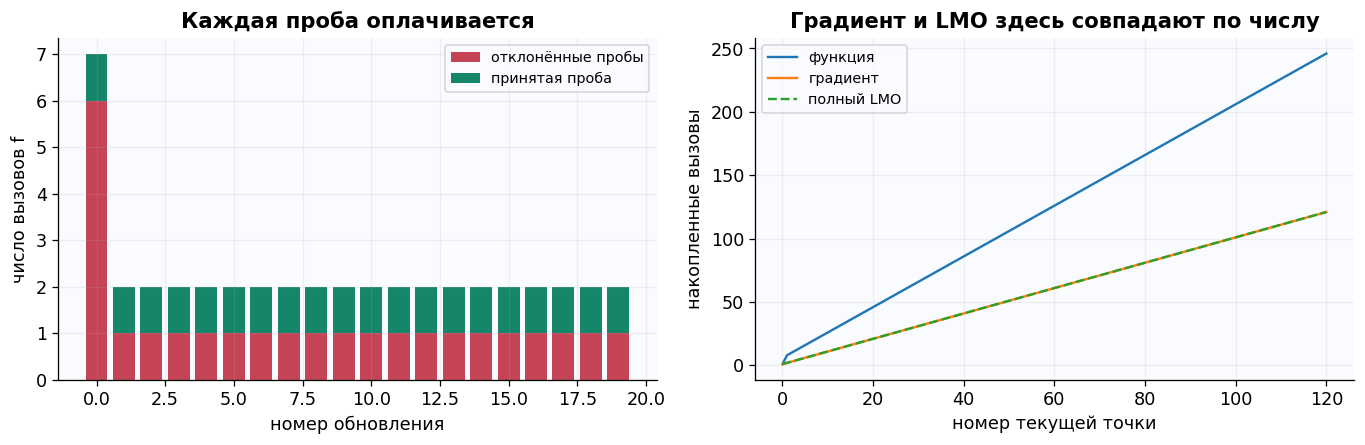

N = 120; вызовов функции: 246; по точному тождеству: 246.


In [9]:
paid_run = run_fw(bowl,bowl_grad,V,[0,1,0],M=.125,eps=1e-5,max_steps=120)
updates = paid_run[:-1]
N = len(updates)
trial_count = sum(len(r['trials']) for r in updates)
nf_identity = 1+2*N+np.log2(updates[-1]['L']/.125)
assert paid_run[-1]['nf'] == 1+trial_count
assert np.isclose(nf_identity,paid_run[-1]['nf'])
assert paid_run[-1]['ng'] == paid_run[-1]['nlmo'] == N+1
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].bar(np.arange(min(N,20)),[len(r['trials'])-1 for r in updates[:20]],
             color=RED,label='отклонённые пробы')
axes[0].bar(np.arange(min(N,20)),np.ones(min(N,20)),
             bottom=[len(r['trials'])-1 for r in updates[:20]],color=GREEN,label='принятая проба')
axes[0].set(xlabel='номер обновления',ylabel='число вызовов f',title='Каждая проба оплачивается')
axes[0].legend(fontsize=9)
for key,label in [('nf','функция'),('ng','градиент'),('nlmo','полный LMO')]:
    axes[1].plot(arr(paid_run,'k'),arr(paid_run,key),label=label,
                 ls='--' if key=='nlmo' else '-')
axes[1].set(xlabel='номер текущей точки',ylabel='накопленные вызовы',title='Градиент и LMO здесь совпадают по числу')
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
print(f'N = {N}; вызовов функции: {paid_run[-1]["nf"]}; '
      f'по точному тождеству: {nf_identity:.0f}.')

## 9. Основная оценка: почему появляется логарифм

> **Обозначения под рукой.** $U_k=f(x_k)-\ell_k$ — вычислимый сертификат, верхняя граница истинной ошибки; $U_0$ — его начальное значение.
> $\varepsilon$ — нужная точность; останавливаемся при $U_k\le\varepsilon$; $N$ — число обновлений до остановки.
> $D$ — диаметр разрешённой области; $H_0,H_1$ задают границу изгиба $H_0+H_1\delta$; $\delta=f-f_Q^*$ — истинная ошибка.
> $M$ — начальная настройка кривизны; $J$ — число двоичных уровней точности; $P$ — оценка цены слишком большого $M$.
> $b$ (или $b_j$ для фазы $j$) — текущий уровень сертификата; $L$ — рабочая оценка кривизны для шага.

Обозначим диаметр области через $D$: это наибольшее расстояние
между разрешёнными точками. На нашем треугольнике $D=\sqrt2$.
Пусть $0<\varepsilon<U_0$.

Теорема 2.3 в текущей статье даёт:

$$N\le P+\left\lceil(6+16H_1D^2)J+
\frac{32H_0D^2}{\varepsilon}\right\rceil,$$

$$J=\left\lceil\log_2\frac{U_0}{\varepsilon}\right\rceil,
\qquad P=\left\lceil\log_2\max\left\{1,\frac{MD^2}{U_0}\right\}\right\rceil.$$

Угловые скобки $\lceil\cdot\rceil$ означают округление вверх.
$J$ — сколько примерно раз нужно разделить начальный сертификат
пополам. $P$ — цена слишком осторожной начальной настройки.
Числа 6, 16, 32 нужны для строгого доказательства; сначала смотрите
на **вид зависимости**, а не на их величину:

$$N\ \lesssim\ P+(1+H_1D^2)\log_2(U_0/\varepsilon)
+H_0D^2/\varepsilon.$$

Знак $\lesssim$ здесь означает «с точностью до постоянных множителей».
Это **верхняя гарантия худшего случая**, не предсказание фактического
числа шагов и не нижняя граница для любых методов.

### Идея доказательства без технических деталей

Разбиваем путь на фазы:
$U_0\to U_0/2\to U_0/4\to\ldots\to\varepsilon$.
На фазе уровня $b$ разрешённая кривизна имеет масштаб $H_0+H_1b$.
Если текущая оценка $L$ уже разумна, гарантированного уменьшения
хватает примерно на $1+H_1D^2+H_0D^2/b$ шагов до следующего уровня.
Вклад $H_1$ примерно одинаков в каждой фазе; вклад $H_0/b$ растёт
при приближении к нулю.

Если же унаследованное $L$ слишком велико, оно делится пополам.
**Потенциал запаздывания** — счётчик оставшихся таких делений.
При переходе на следующий двоичный уровень счётчик увеличивается
не более чем на единицу: не нужно заново платить полную цену
настройки на каждом уровне.

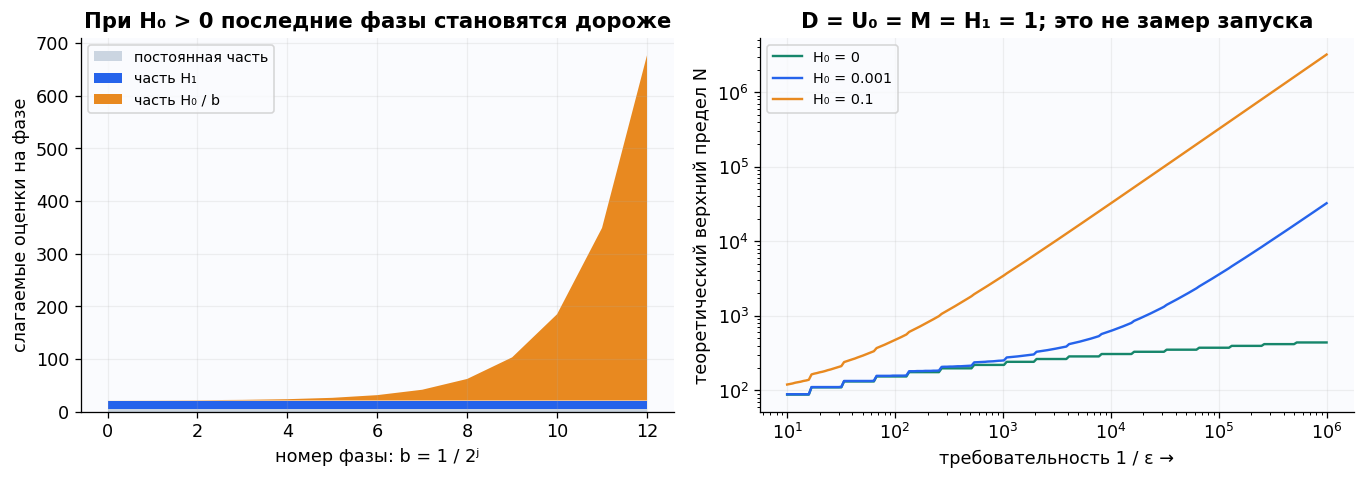

In [10]:
levels = np.arange(13)
b = 2.**(-levels)
h0, h1, diameter = .01, 1., 1.
fig, axes = plt.subplots(1,2,figsize=(12,4.3))
# This is the per-phase proof estimate, not measured iterations.
base_cost = np.full_like(b,5.)
h1_cost = np.full_like(b,16*h1*diameter**2)
h0_cost = 16*h0*diameter**2/b
axes[0].stackplot(levels,base_cost,h1_cost,h0_cost,
                  labels=['постоянная часть','часть H₁','часть H₀ / b'],
                  colors=['#cbd5e1',BLUE,ORANGE])
axes[0].set(xlabel='номер фазы: b = 1 / 2ʲ',ylabel='слагаемые оценки на фазе',
            title='При H₀ > 0 последние фазы становятся дороже')
axes[0].legend(fontsize=9,loc='upper left')
eps_grid = np.logspace(-1,-6,200)
J = np.ceil(np.log2(1/eps_grid))
for h0,color in [(0,GREEN),(.001,BLUE),(.1,ORANGE)]:
    bound = np.ceil((6+16)*J+32*h0/eps_grid)
    axes[1].loglog(1/eps_grid,bound,color=color,label=f'H₀ = {h0:g}')
axes[1].set(xlabel='требовательность 1 / ε →',ylabel='теоретический верхний предел N',
            title='D = U₀ = M = H₁ = 1; это не замер запуска')
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

**Почему это лучше грубой глобальной подстановки:** в примере
$\cosh x-1$ на $[-R,R]$ глобальное $L_Q=\cosh R$ растёт
экспоненциально по $R$. Если просто подставить $H_0=L_Q,H_1=0$
в ту же теорему, потеряем много информации. Пара $H_0=H_1=1$
сохраняет уменьшение кривизны; в статье соответствующая оценка
полиномиальна по $R$ при фиксированных $\varepsilon,M$.
Это сравнение **гарантий**. Точная минимизация на отрезке решает
этот конкретный одномерный пример за один шаг.

Оценка числа функций при $N\ge1$:

$$N_f\le1+2N+\left\lceil\log_2\max\left\{1,
\frac{2(H_0+H_1U_0)}M\right\}\right\rceil.$$

При нуле обновлений достаточно одной начальной проверки: один
вызов функции, градиента и LMO. Всё это предполагает точные оракулы
и арифметику; десятичные вычисления ноутбука лишь иллюстрируют теорию.

## 10. Зачем отдельно обсуждается начальное M

> **Обозначения под рукой.** $M$ — начальная настройка; $L$ — текущая пробная кривизна, которую алгоритм делит пополам или удваивает.
> $x_0$ — старт; $U_0$ — начальный сертификат; $\varepsilon$ — порог остановки $U_k\le\varepsilon$.
> $D$ — диаметр области; $N$ — число обновлений; $\alpha$ — доля шага к LMO-точке.

Большое $M$ сначала даёт слишком маленькие шаги. Это видно даже
на прямой $f(x)=-x$ на $[-1,1]$ — изгиба вообще нет!

Из $x_0=-1$ нужно дойти к $1$. Каждая проба проходит, но слишком
осторожный алгоритм постепенно ослабляет ограничение, деля $L$
пополам. В статье для $0<\varepsilon<2$ получено точное число:

$$N=\left\lceil\log_2\big(1+M(1-\varepsilon/2)\big)\right\rceil.$$

Это ограничение **конкретного правила настройки**, а не трудность
линейной оптимизации: шаг $\alpha=1$ сразу решает задачу.
Необязательная инициализация $M=U_0/D^2$ здесь даёт $M=1/2$
и один шаг. Она использует уже оплаченные начальные данные и диаметр,
но не читает оптимум. Гарантии допускают и любое другое $M>0$.

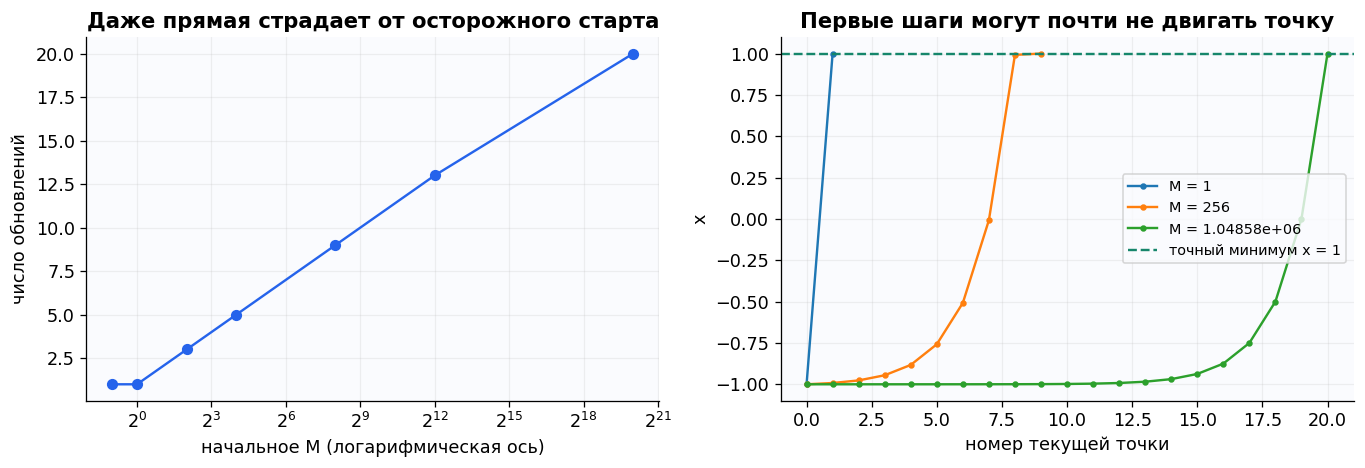

M,обновления в запуске,точная формула,вызовы f
0.5,1,1,2
1,1,1,2
4,3,3,4
16,5,5,6
256,9,9,10
4096,13,13,14
1.04858e+06,20,20,21


In [11]:
linear_V = np.array([[-1.],[1.]])
linear_f = lambda x: -x[0]
linear_g = lambda x: np.array([-1.])
M_values = [.5,1,4,16,256,4096,2.**20]
linear_runs = [run_fw(linear_f,linear_g,linear_V,[1,0],M=M,eps=1e-4,max_steps=100)
               for M in M_values]
formula = [math.ceil(math.log2(1+M*(1-1e-4/2))) for M in M_values]
assert [len(t)-1 for t in linear_runs] == formula
fig, axes = plt.subplots(1,2,figsize=(12,4.2))
axes[0].semilogx(M_values,formula,'o-',base=2,color=BLUE)
axes[0].set(xlabel='начальное M (логарифмическая ось)',ylabel='число обновлений',
            title='Даже прямая страдает от осторожного старта')
for M in [1.,256.,2.**20]:
    t = linear_runs[M_values.index(M)]
    axes[1].plot(arr(t,'k'),arr(t,'x')[:,0],'o-',ms=3,label=f'M = {M:g}')
axes[1].axhline(1,color=GREEN,ls='--',label='точный минимум x = 1')
axes[1].set(xlabel='номер текущей точки',ylabel='x',title='Первые шаги могут почти не двигать точку')
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
table(['M','обновления в запуске','точная формула','вызовы f'],
      [(f'{M:g}',len(t)-1,n,t[-1]['nf']) for M,t,n in zip(M_values,linear_runs,formula)])

## 11. AFW: иногда нужно не добавлять хорошее, а убирать плохое

> **Обозначения под рукой.** $x=\sum_v\lambda_v v$ — текущая смесь вершин; $\lambda_v$ — вес вершины; $S$ — вершины с положительным весом.
> $s$ — лучшая точка по полному LMO; $v$ — худшая активная вершина; $\alpha$ — длина выбранного шага; $\alpha_{\max}$ — её допустимый предел.
> $G$ — полный FW-зазор для сертификата; $g$ — зазор выбранного FW- или away-направления; $L$ — рабочая кривизна.
> $S_0$ — начальное активное множество; $|S_0|$ — число атомов в нём; $m$ здесь — число хороших шагов; $N$ — число всех обновлений.

Любая точка нашего треугольника — смесь его вершин:

$$x=\lambda_A A+\lambda_B B+\lambda_C C,\quad
\lambda_v\ge0,\quad\sum_v\lambda_v=1.$$

Вершину в такой записи называют **атомом**. Атомы с положительным
весом — активное множество $S$. Это описание алгоритмического
представления точки; не путайте его с активными ограничениями задачи.

Обычный FW добавляет вес выбранной вершине $s$ и умножает остальные
веса на $1-\alpha$. Если ошибочная вершина уже есть в смеси,
её вес может уменьшаться очень медленно.

**Away-step FW (AFW)** разрешает второе движение:
найти худшую активную вершину
$v\in\arg\max_{a\in S}\langle\nabla f(x),a\rangle$
и пойти **от неё** по направлению $x-v$.
Сравниваем предсказанное уменьшение двух направлений и выбираем
большее; при равенстве берём FW.

Для away-направления вес $v$ после шага:

$$\lambda_v'=\lambda_v-\alpha(1-\lambda_v).$$

Поэтому максимально допустимая длина
$\alpha_{\max}=\lambda_v/(1-\lambda_v)$.
При таком шаге вес становится **ровно нулём**, атом удаляется.
Это *drop step*, максимальное удаление. Верхняя граница away-шага
может быть больше единицы: это уже не отрезок к новой вершине.

Применяется тот же backtracking, только с выбранным зазором $g$
и ограничением $\alpha\le\alpha_{\max}$. Для сертификата всё равно
нужен **полный FW-зазор G**, а не только поиск по активным атомам.
Просмотр активного множества — отдельная вычислительная работа.

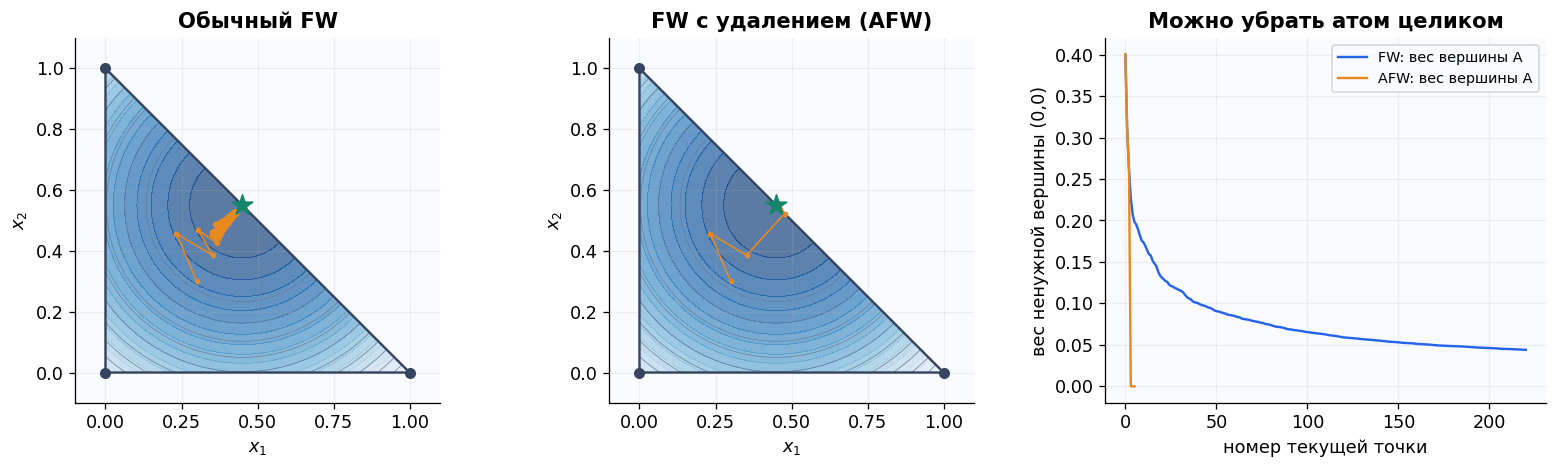

FW: обновлений 220, удалений 0, ошибка 0.000486, сертификат 0.00108
AFW: обновлений 5, удалений 1, ошибка 0, сертификат 0


In [12]:
edge_target = np.array([.45,.55])
def edge_f(x):
    return .5*np.sum((np.asarray(x)-edge_target)**2,axis=-1)
def edge_g(x):
    return x-edge_target
edge_fw = run_fw(edge_f,edge_g,V,[.4,.3,.3],M=1,eps=1e-8,max_steps=220)
edge_afw = run_fw(edge_f,edge_g,V,[.4,.3,.3],M=1,eps=1e-8,max_steps=220,away=True)
fig, axes = plt.subplots(1,3,figsize=(14,4.2))
for ax,t,title in [(axes[0],edge_fw,'Обычный FW'),(axes[1],edge_afw,'FW с удалением (AFW)')]:
    draw_triangle(ax,edge_f,mark_opt=False)
    path = arr(t,'x')
    ax.plot(*path.T,'o-',color=ORANGE,ms=2.5,lw=1)
    ax.scatter(*edge_target,marker='*',s=180,color=GREEN,zorder=6)
    ax.set_title(title)
for t,label,color in [(edge_fw,'FW: вес вершины A',BLUE),(edge_afw,'AFW: вес вершины A',ORANGE)]:
    axes[2].plot(arr(t,'k'),arr(t,'weights')[:,0],label=label,color=color)
axes[2].set(xlabel='номер текущей точки',ylabel='вес ненужной вершины (0,0)',
            title='Можно убрать атом целиком')
axes[2].legend(fontsize=9)
plt.tight_layout(); plt.show()
for name,t in [('FW',edge_fw),('AFW',edge_afw)]:
    drops = sum(r.get('drop',False) for r in t)
    print(f'{name}: обновлений {len(t)-1}, удалений {drops}, '
          f'ошибка {t[-1]["f"]:.3g}, сертификат {t[-1]["U"]:.3g}')

Это один учебный пример преимущества удаления, не доказательство,
что AFW всегда быстрее FW. При $H_0>0$ удаление неправильных атомов
не обязано решить задачу точно: внутри правильной грани ещё может
оставаться непостоянная целевая функция.

**Как статья считает шаги:** обычный FW-шаг добавляет не более одного
атома, максимальное удаление убирает один, активное множество не пусто.
Поэтому удалений не может быть произвольно много относительно
числа остальных шагов. Если хороших шагов $m$, то

$$N\le2m+|S_0|-1.$$

Здесь «хороший» — техническое название шага, который не является
максимальным удалением. Максимальные удаления тоже полезны!
Это стандартный подсчёт AFW, позволяющий перенести фазовый анализ.

## 12. Почему ошибка уже мала, а сертификат ещё большой

> **Обозначения под рукой.** $\delta=f(x)-f_Q^*$ — истинная ошибка; $G$ — FW-зазор; $U=f(x)-\ell$ — сертификат с памятью. Имеем $\delta\le U\le G$.
> $E(\delta)$ — наибольшая допустимая граница для $G$ при данной ошибке; $D$ — диаметр области.
> $H_0,H_1$ — константы границы кривизны; $a=D\sqrt{H_1}$ и $c=H_0/H_1$ — сокращения в формуле при $H_1>0$.
> $t$ в квадратичном примере — координата точки; ниже, в разборе отрезка, $t\in[0,1]$ — доля движения к LMO-точке.

Мы знаем $\delta\le U\le G$. Но бывает ли обратный контроль:
**если ошибка уже мала, обязан ли сертификат скоро стать малым?**

Пример $f(x)=x^2/2$ на $[-1,1]$. В точке $x=t>0$ LMO выбирает
$s=-1$, поэтому

$$\delta=t^2/2,\qquad G=t(1+t).$$

При $t=0.001$ ошибка около $5\cdot10^{-7}$, а FW-зазор около
$0.001$. Если это первое наблюдение, $U=G$: памяти ещё нет.
Отношение $G/\delta$ растёт при $t\to0$.
По прошлой истории $U$ может стать лучше, поэтому этот пример
не доказывает неизбежную медленность любого сертификата или алгоритма.

В статье выведена **точная по классу поточечная огибающая** $E$:

$$G\le E(\delta).$$

«Огибающая» — верхняя кривая для всех допустимых функций.
«Точная по классу» — при каждом наборе допустимых параметров и
положительной ошибке есть одномерный пример с равенством.
Это оптимальность **неравенства**, а не алгоритма по числу шагов
и не заявление библиографического первенства.

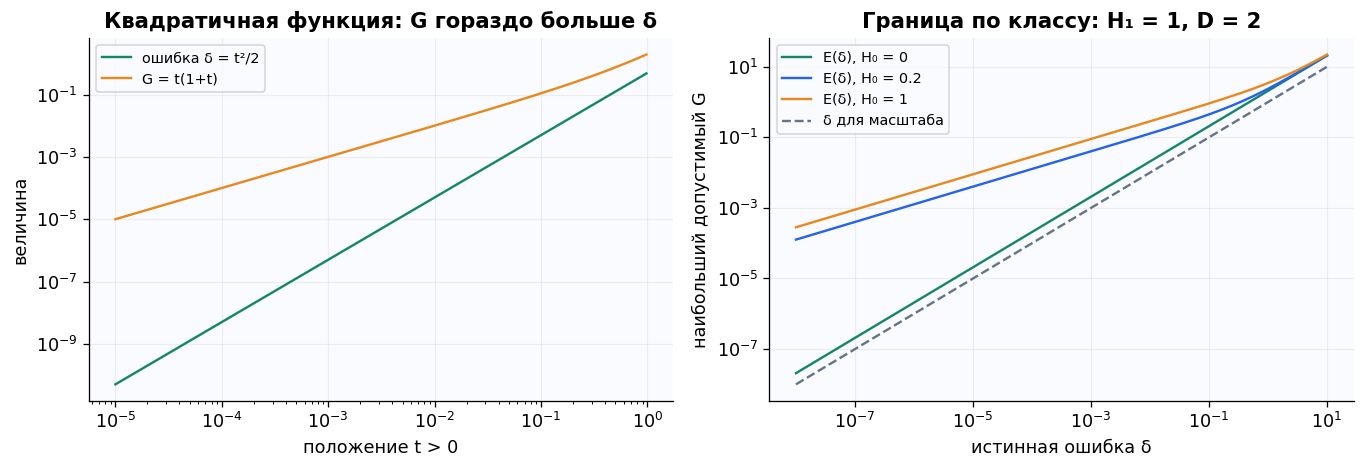

t,истинная ошибка δ,G = U при первом наблюдении,G / δ
0.1,0.005,0.11,22
0.01,5e-05,0.0101,202
0.001,5e-07,0.001001,2002


In [13]:
def envelope(delta,H0,H1,D):
    delta = np.asarray(delta,dtype=float)
    if H1==0:
        A = D*D*H0
        if A==0:
            return delta.copy()
        return np.where(2*delta<=A,np.sqrt(2*A*delta),delta+A/2)
    a = D*np.sqrt(H1)
    if H0==0:
        return a/np.tanh(a)*delta
    c = H0/H1
    return np.where(delta<=c*(np.cosh(a)-1),
                    D*np.sqrt(2*H0*delta+H1*delta**2),
                    a/np.tanh(a)*delta+a*c*np.tanh(a/2))

delta_grid = np.logspace(-8,1,400)
t_grid = np.logspace(-5,-.01,200)
fig, axes = plt.subplots(1,2,figsize=(12,4.2))
axes[0].loglog(t_grid,t_grid**2/2,color=GREEN,label='ошибка δ = t²/2')
axes[0].loglog(t_grid,t_grid*(1+t_grid),color=ORANGE,label='G = t(1+t)')
axes[0].set(xlabel='положение t > 0',ylabel='величина',title='Квадратичная функция: G гораздо больше δ')
axes[0].legend(fontsize=9)
for h0,color in [(0,GREEN),(.2,BLUE),(1,ORANGE)]:
    axes[1].loglog(delta_grid,envelope(delta_grid,h0,1,2),color=color,label=f'E(δ), H₀ = {h0:g}')
axes[1].loglog(delta_grid,delta_grid,color='#64748b',ls='--',label='δ для масштаба')
axes[1].set(xlabel='истинная ошибка δ',ylabel='наибольший допустимый G',
            title='Граница по классу: H₁ = 1, D = 2')
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
table(['t','истинная ошибка δ','G = U при первом наблюдении','G / δ'],
      [(f'{t:g}',f'{t*t/2:.4g}',f'{t*(1+t):.4g}',f'{2*(1+t)/t:.0f}')
       for t in [.1,.01,.001]])

Для желающих увидеть формулу: при $H_1>0$ положим
$a=D\sqrt{H_1}$, $c=H_0/H_1$. Тогда

$$E(\delta)=\begin{cases}
D\sqrt{2H_0\delta+H_1\delta^2},&\delta\le c(\cosh a-1),\\
a\delta\coth a+ac\tanh(a/2),&\delta>c(\cosh a-1).
\end{cases}$$

$\tanh a=\sinh a/\cosh a$, $\coth a=1/\tanh a$ — обычные
гиперболические функции. Их не нужно заучивать, чтобы понять смысл:

- при $H_0>0$ и малой ошибке граница имеет масштаб $\sqrt\delta$;
- при $H_0=0$ она линейна: $E(\delta)=a\coth(a)\delta$.

**Откуда берётся формула:** прослеживаем функцию по отрезку к
LMO-вершине: $h(t)=f(x+t(s-x))-f_Q^*$.
Тогда $h(0)=\delta$, $h'(0)=-G$, $h(t)\ge0$ и
$h''(t)\le D^2(H_0+H_1h(t))$.
Слишком большой начальный отрицательный наклон заставил бы функцию
стать отрицательной до конца отрезка — ниже минимума. Сравнение с
решением уравнения с равенством и даёт допустимую границу наклона.

Ниже два **достигающих** примера: в первом минимум внутри отрезка,
во втором — на правом конце. Кривая действительно касается границы
по зазору; это не просто численно подобранный верхний график.

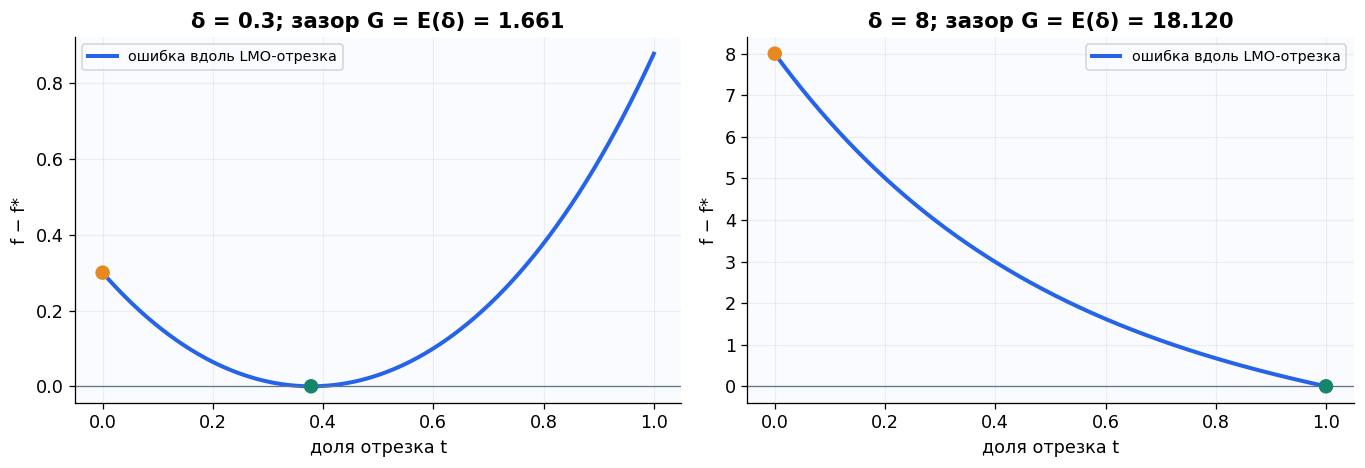

In [14]:
fig, axes = plt.subplots(1,2,figsize=(12,4.2))
D, H0, H1 = 2., 1., 1.
a, c = D*np.sqrt(H1), H0/H1
tt = np.linspace(0,1,600)
for ax,delta in zip(axes,[.3,8.]):
    G = float(envelope(delta,H0,H1,D))
    if delta<=c*(np.cosh(a)-1):
        t_star = np.arccosh(1+delta/c)/a
        h = c*(np.cosh(a*(tt-t_star))-1)
        actual_gap = a*c*np.sinh(a*t_star)
        endpoint_minimum = c*(np.cosh(0.)-1)
    else:
        t_star = 1.
        B = ((delta+c)*np.cosh(a)-c)/np.sinh(a)
        h = (delta+c)*np.cosh(a*tt)-B*np.sinh(a*tt)-c
        actual_gap = a*B
        endpoint_minimum = (delta+c)*np.cosh(a)-B*np.sinh(a)-c
    assert h.min() >= -1e-10
    assert abs(endpoint_minimum) < 1e-10
    assert abs(actual_gap-G) < 1e-10
    ax.plot(tt,h,color=BLUE,lw=2.5,label='ошибка вдоль LMO-отрезка')
    ax.scatter([0,t_star],[delta,0],color=[ORANGE,GREEN],s=65,zorder=5)
    ax.axhline(0,color='#64748b',lw=.8)
    ax.set(xlabel='доля отрезка t',ylabel='f − f*',
           title=f'δ = {delta:g}; зазор G = E(δ) = {G:.3f}')
    ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 13. Когда получается геометрическая сходимость

> **Обозначения под рукой.** $\delta_k=f(x_k)-f_Q^*$ — истинная ошибка; $G_k$ — полный FW-зазор; $U_k=f(x_k)-\ell_k$ — вычислимый сертификат.
> $g_k$ — зазор выбранного FW- или away-направления; $\kappa>0$ — константа дополнительного условия $g_k^2\ge2\kappa\delta_k$.
> $E$ переводит ошибку в границу FW-зазора; $\eta_\varepsilon=E^{-1}(\varepsilon)$ — достаточная истинная ошибка для сертификата $U\le\varepsilon$.
> $U_0$ — начальный сертификат; $D$ — диаметр области; $H_0,H_1$ — константы границы кривизны; $M$ — начальная настройка.
> $J_*$ — число фаз до $\eta_\varepsilon$; $P_*$ — цена инициализации в этой оценке; $|S_0|$ — число начальных активных атомов; $N$ — число обновлений.

«Линейная скорость сходимости» — термин, означающий уменьшение
ошибки примерно в одно и то же число раз, например
$1,1/2,1/4,1/8,\ldots$. На обычной оси это экспоненциальное
падение; на графике логарифма ошибки получается примерно прямая.
В этом ноутбуке называем её **геометрической**, чтобы не спутать
с линейной функцией.

Для соответствующей AFW-теоремы нужно дополнительное условие:

$$g_k^2\ge2\kappa\delta_k,\qquad \kappa>0.$$

Здесь $g_k$ — зазор **выбранного** FW- или away-направления.
Условие говорит: пока ошибка есть, доступное направление даёт
достаточный сигнал для спуска. Оно не следует из одного лишь
ограничения кривизны. Его дают, например, сильная выпуклость функции
в сочетании с геометрией многогранника или подходящая оценка роста
относительно множества решений. Геометрия многогранника определяет,
насколько хорошо допустимые направления способны помочь.

В доказательстве сначала снижают истинную ошибку до
$\eta_\varepsilon=E^{-1}(\varepsilon)$.
По пункту 12 это гарантирует $U\le G\le\varepsilon$.
Даже если $\eta_\varepsilon$ имеет масштаб $\varepsilon^2$,
геометрическая сходимость требует лишь логарифмического числа фаз:
$\log(1/\varepsilon^2)=2\log(1/\varepsilon)$.

Полная формула статьи при $H_0+H_1>0$ и $0<\varepsilon<U_0$:

$$N\le2\left\lceil P_*+
(6+4H_0D^2/\kappa)J_*+8H_1D^2U_0/\kappa\right\rceil+|S_0|-1,$$

$$J_*=\left\lceil\log_2(U_0/\eta_\varepsilon)\right\rceil,\quad
P_*=\left\lceil\log_2\max\{1,M/[2(H_0+H_1U_0)]\}\right\rceil.$$

При фиксированных задаче и старте зависимость от точности
логарифмическая. Отдельная фазовая цена $H_1$ пропорциональна $U_0$;
кроме того, $H_1$ входит в $\eta_\varepsilon$ и $J_*$.
Эта гарантия не обязательно численно лучше обычной выпуклой оценки:
маленькое $\kappa$ может дать большой предел.
**Алгоритму $\kappa$ тоже не сообщают.**

## 14. Почему H₀ = 0 — особый мир: AFW может закончить точно

> **Обозначения под рукой.** $\delta(x)=f(x)-f_Q^*$ — истинная ошибка; $H_0=0$ означает границу изгиба $\|\nabla^2f(x)\|\le H_1\delta(x)$.
> $x^*$ — любой оптимум; $X^*$ — всё множество оптимумов; $g^*=\nabla f(x^*)$ — общий градиент в них, не FW-зазор.
> $\lambda_v$ — вес атома $v$; $U=f(x)-\ell$ — сертификат; $G$ — полный FW-зазор; $L$ — рабочая кривизна; $M$ — её начальная настройка.
> $\tau$ — порог сертификата для гарантированного удаления; $m$ здесь — положительный запас отделения плохих атомов, не число шагов.
> $h>0$ в контрпримере — коэффициент квадратичной функции, равный её $H_0$; $\varepsilon$ — допуск остановки.

Это сильнее, чем сказать «$H_0$ очень маленькое».
При $H_0=0$ условие $\|\nabla^2 f\|\le H_1\delta$ заставляет
гессиан в оптимуме быть нулевым.

Статья доказывает ещё больше. Для непостоянной функции на $Q$
все минимумы образуют одну **экспонированную грань**:

$$X^*=\{x\in Q:\langle g^*,x-x^*\rangle=0\},\qquad
g^*=\nabla f(x^*).$$

Простыми словами: одна опорная прямая/плоскость выделяет край области,
и **весь этот край оптимален**. В разных оптимумах один и тот же
градиент $g^*$. Если бы $g^*=0$, функция была бы постоянной на $Q$.
Поэтому для непостоянного случая оптимум не может лежать в
относительной внутренности области.

Почему? От оптимума идём по отрезку к точке той же опорной
плоскости. Начальное значение ошибки и начальный наклон равны нулю.
Ограничение изгиба через саму ошибку не позволяет функции начать
расти из такого состояния. Значит, весь этот отрезок оптимален.
На отрезке между оптимумами гессиан нулевой, поэтому и градиент
не меняется. В статье это оформлено сравнением дифференциальных
неравенств, а не предположением по рисунку.

### Совсем простой нелинейный пример

На нашем треугольнике возьмём $f(x)=x_1+x_1^3$.
Минимум ноль на **всём левом ребре** $x_1=0$.
Гессиан имеет норму $6x_1\le6(x_1+x_1^3)$: подходят $H_0=0,H_1=6$.
Градиент в оптимуме — $(1,0)$, он не нулевой.

В смеси вершин мешает только вес вершины $(1,0)$.
Как только AFW удалит этот атом, **все оставшиеся смеси оптимальны**.
Не нужно продолжать искать одну особенную точку на ребре.

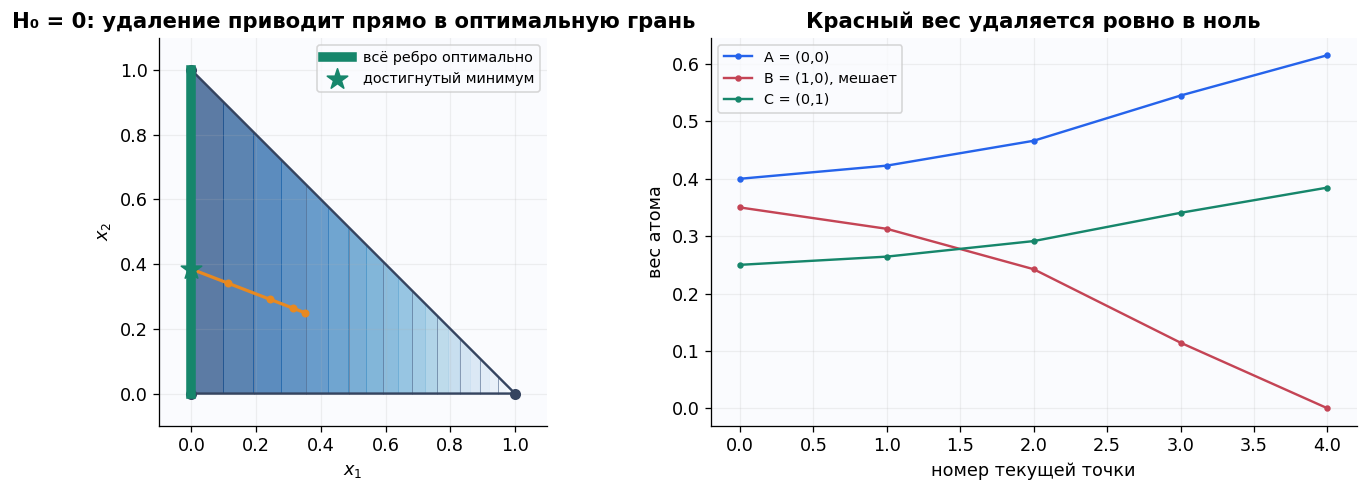

k,тип следующего шага,вес B,U,принятый L
0,away,0.35,0.478625,32
1,away,0.312773,0.404565,16
2,away,0.242348,0.285049,8
3,удаление,0.11427,0.118746,4
4,остановка,0,0,—


In [15]:
def zero_f(x):
    t = np.asarray(x)[...,0]
    return t+t**3
def zero_g(x):
    return np.array([1+3*x[0]**2,0.])
zero_run = run_fw(zero_f,zero_g,V,[.4,.35,.25],M=64.,eps=0.,max_steps=90,away=True)
assert zero_run[-1]['U']==0 and zero_run[-1]['x'][0]==0
assert any(r.get('drop',False) for r in zero_run)
fig, axes = plt.subplots(1,2,figsize=(12,4.4))
draw_triangle(axes[0],zero_f,mark_opt=False)
axes[0].plot([0,0],[0,1],color=GREEN,lw=6,label='всё ребро оптимально',zorder=5)
path = arr(zero_run,'x')
axes[0].plot(*path.T,'o-',color=ORANGE,lw=2,ms=4,zorder=6)
axes[0].scatter(*path[-1],marker='*',s=180,color=GREEN,zorder=7,label='достигнутый минимум')
axes[0].set_title('H₀ = 0: удаление приводит прямо в оптимальную грань')
axes[0].legend(fontsize=9,loc='upper right')
weights = arr(zero_run,'weights')
for j,label,color in [(0,'A = (0,0)',BLUE),(1,'B = (1,0), мешает',RED),(2,'C = (0,1)',GREEN)]:
    axes[1].plot(arr(zero_run,'k'),weights[:,j],'o-',label=label,color=color,ms=3)
axes[1].set(xlabel='номер текущей точки',ylabel='вес атома',title='Красный вес удаляется ровно в ноль')
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
table(['k','тип следующего шага','вес B','U','принятый L'],
      [(r['k'],'удаление' if r.get('drop') else r.get('kind','остановка'),
        f"{r['weights'][1]:.6g}",f"{r['U']:.6g}",f"{r['L']:.6g}" if 'L' in r else '—')
       for r in zero_run])

### Почему конечное число шагов гарантировано, а не только видно в примере

Для конечного множества атомов есть положительный запас $m$,
отделяющий неоптимальные вершины от оптимальной опорной плоскости.
Статья выписывает порог $\tau>0$ и доказывает:

1. Фазовый анализ приводит к $U\le\tau$ за конечное число шагов.
2. В этой области AFW выбирает удаление неоптимального атома.
3. Слишком осторожное унаследованное $L$ конечное число раз делится
   пополам, после чего away-шаги достигают допустимой границы.
4. Каждый такой шаг удаляет один неоптимальный атом. Их конечное число.
5. Когда плохих атомов не осталось, точка оптимальна и финальная
   проверка даёт $G=U=0$.

Гарантия не зависит от запрошенной точности: алгоритм можно
рассматривать с нулевым допуском. Саму общую идею идентификации
активного множества статья не объявляет новой.

Нужны **конечное множество атомов**, непостоянная целевая функция,
точные оракулы, точная арифметика и выполнение условия на всём $Q$.
На диске бесконечно много крайних точек; этот подсчёт неприменим.
Округление чисел в ноутбуке не является доказательством точности.
В нашем примере ноль возникает именно из обнуления веса при
допустимом максимальном удалении, без отсечения «маленьких» весов.

### Почему нельзя просто заменить H₀ = 0 на «очень маленькое H₀»

В статье есть контрпример $f(x)=h x^2/2$ на $[-1,1]$, $h>0$.
При подходящем старте и $M=3h$ заданное backtracking-правило даёт
$x_{k+1}=x_k/3$. Тогда $x_k\to0$, но ни одно конечное $x_k$
не равно нулю. Это верно и для сколь угодно малого $h=H_0>0$.
Ниже считаем дроби точно: исчезновение точки из-за машинного
округления не перепутается с конечным достижением минимума.

k,точная координата x_k,десятичная запись,точный минимум достигнут?
0,1/2,0.50000000,нет
1,1/6,0.16666667,нет
2,1/18,0.05555556,нет
3,1/54,0.01851852,нет
4,1/162,0.00617284,нет
5,1/486,0.00205761,нет
6,1/1458,0.00068587,нет
7,1/4374,0.00022862,нет
8,1/13122,0.00007621,нет


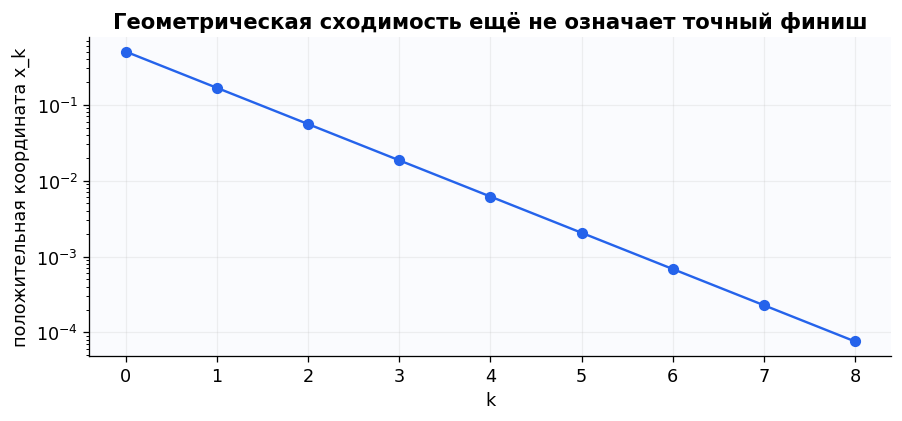

In [16]:
x0_fraction = Fraction(1,2)
exact_points = [x0_fraction/(3**k) for k in range(9)]
assert all(x>0 for x in exact_points)
table(['k','точная координата x_k','десятичная запись','точный минимум достигнут?'],
      [(k,str(x),f'{float(x):.8f}','нет') for k,x in enumerate(exact_points)])
fig, ax = plt.subplots(figsize=(9,3.6))
ax.semilogy(range(9),[float(x) for x in exact_points],'o-',color=BLUE)
ax.set(xlabel='k',ylabel='положительная координата x_k',
       title='Геометрическая сходимость ещё не означает точный финиш')
plt.show()

## 15. Что показывают настоящие эксперименты статьи

> **Обозначения под рукой.** $x$ — коэффициенты модели; $f(x)$ — обучающие потери; $a_i,t_i$ — признаки и нормированный отклик наблюдения $i$.
> $m$ здесь — число наблюдений; $\mu$ — коэффициент квадратичной регуляризации и известная нижняя граница сильной выпуклости.
> $R$ — радиус ограничения $\|x\|_1\le R$; $R_*$ — норма независимо найденного безусловного оптимума; $D$ — диаметр области.
> $U=f(x)-\ell$ — сертификат; $\varepsilon=10^{-5}$ — целевая точность; $M$ — начальная настройка; $H_0,H_1$ — константы границы кривизны.
> FW — шаг к LMO-точке; AFW — вариант с удалением атомов; BT — подбор шага пробами; Q — шаг с известными $H_0,H_1$; AC-FW — другой адаптивный алгоритм сравнения.

Дальше читаем **готовые CSV проекта**, оптимизаторы на реальных данных
заново не запускаем. Учебные картинки выше были отдельными примерами.

Реальные задачи используют счётные данные: прокаты велосипедов Seoul
и интенсивность движения Metro. Вектор $x$ — коэффициенты модели.
Функция — выпуклые пуассоновские потери с квадратичной регуляризацией:

$$f(x)=\frac1m\sum_i
\left[e^{a_i^\top x}-t_i a_i^\top x+c_i\right]
+\frac\mu2\|x\|^2,\qquad \|x\|_1\le R.$$

Здесь $a_i$ — признаки одного наблюдения, $t_i$ — нормированный
счётный отклик, $c_i$ — не влияющая на шаги константа,
$\mu=0.01$. Экспонента связывает линейный прогноз с положительной
интенсивностью. Это задача **минимизации обучающей функции**;
таблицы не доказывают лучшее качество прогноза на новых данных.
Норма $\|x\|_1=\sum_j|x_j|$ ограничивает сумму модулей коэффициентов.
В двух измерениях её шар — ромб; вершины в общем случае $\pm Re_j$.
LMO выбирает координату с наибольшим модулем градиента и нужный знак.

Радиус $R_*/2$ делает ограничение активным, $2R_*$ даёт внутренний
оптимум; $R_*$ найден независимым численным эталоном.
Для каждого радиуса перебраны знаковые координатные старты:
30 для Seoul, 24 для Metro. Всего **108 условий и 756 запусков
семи методов**. Эти старты не являются 108 независимыми наборами данных.

| Обозначение | Что знает и делает метод |
| --- | --- |
| FW-BT, fixed | Обычный FW с backtracking, начальное M = 1 |
| FW-BT, cert | То же с M = U₀/D² |
| AFW-BT, fixed / cert | Те же настройки, но разрешены away-шаги |
| FW-Q / AFW-Q | Информированный контроль: знает H₀,H₁ и берёт L = H₀ + H₁U |
| AC-FW | Другой опубликованный адаптивный FW; его подготовка тоже оплачивается |

Сравниваем при **1000 вызовов функции**, а не «1000 итераций у всех».
Цель $U\le10^{-5}$. Неуспешные старты включены в графики.
После успешной остановки достигнутое значение переносится на
следующие бюджеты, а не запускается дальше.

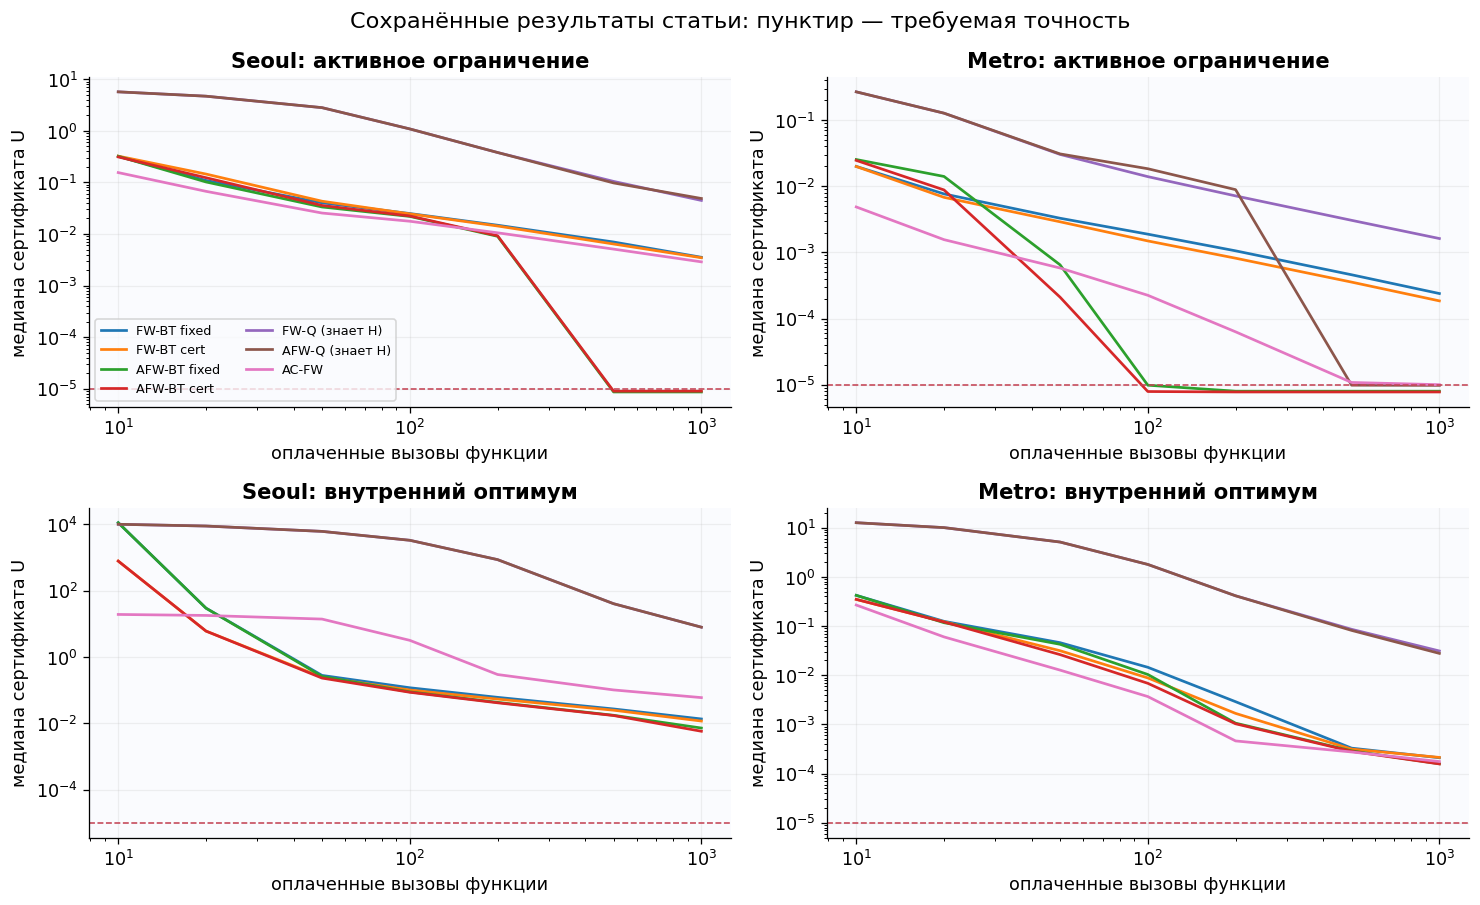

успех при 1000 f,Seoul активный,Metro активный,Seoul внутренний,Metro внутренний
FW-BT fixed,0 / 30,2 / 24,0 / 30,0 / 24
FW-BT cert,0 / 30,3 / 24,0 / 30,0 / 24
AFW-BT fixed,30 / 30,24 / 24,0 / 30,0 / 24
AFW-BT cert,30 / 30,24 / 24,0 / 30,0 / 24
FW-Q (знает H),0 / 30,1 / 24,0 / 30,0 / 24
AFW-Q (знает H),0 / 30,24 / 24,0 / 30,0 / 24
AC-FW,0 / 30,13 / 24,0 / 30,0 / 24


In [17]:
def find_project():
    for ancestor in [Path.cwd(), *Path.cwd().parents]:
        for candidate in [ancestor, ancestor/'PART3']:
            if (candidate/'Paper/article.tex').is_file() and (candidate/'Work').is_dir():
                return candidate.resolve()
    return None

project_root = find_project()
read_inputs = []
def read_csv(relative):
    path = project_root/relative
    with path.open(encoding='utf-8',newline='') as stream:
        records = list(csv.DictReader(stream))
    read_inputs.append(relative)
    return records

METHOD_LABELS = {
    'FW_BT_fixed':'FW-BT fixed', 'FW_BT_certificate':'FW-BT cert',
    'AFW_BT_fixed':'AFW-BT fixed', 'AFW_BT_certificate':'AFW-BT cert',
    'FW_Q':'FW-Q (знает H)', 'AFW_Q':'AFW-Q (знает H)', 'AC_FW':'AC-FW',
}
if project_root is None:
    display(Markdown('**Исходный проект рядом не найден.** Учебные примеры работают '
                     'без него. Для пересчёта следующих графиков откройте ноутбук '
                     'внутри PART3; сохранённые результаты можно читать и без пересчёта.'))
else:
    summaries = read_csv('Work/multidata_results/summary.csv') + read_csv('Work/count_comparator_results/summary.csv')
    budget_records = read_csv('Work/multidata_results/budget.csv') + read_csv('Work/count_comparator_results/budget.csv')
    primary = [r for r in budget_records if r['oracle']=='function_evals' and r['budget']=='1000']
    identities = {(r['dataset'],r['radius_ratio'],r['start'],r['method']) for r in summaries}
    assert len(summaries)==len(identities)==756
    assert len({key[:3] for key in identities})==108
    assert len(primary)==756 and all(r['budget_reached_or_certified']=='True' for r in primary)
    groups = [('seoul','0.5'),('metro','0.5'),('seoul','2.0'),('metro','2.0')]
    fig, axes = plt.subplots(2,2,figsize=(13,8))
    colors = plt.cm.tab10(np.arange(7))
    for ax,(dataset,radius) in zip(axes.flat,groups):
        for color,(method,label) in zip(colors,METHOD_LABELS.items()):
            chosen = [r for r in budget_records if r['dataset']==dataset
                      and r['radius_ratio']==radius and r['method']==method
                      and r['oracle']=='function_evals' and 10<=int(r['budget'])<=1000
                      and r['budget_reached_or_certified']=='True']
            budgets = sorted({int(r['budget']) for r in chosen})
            medians = [np.median([float(r['certificate']) for r in chosen if int(r['budget'])==b])
                       for b in budgets]
            ax.loglog(budgets,positive(medians),color=color,label=label,lw=1.7)
        ax.axhline(1e-5,color=RED,ls='--',lw=1)
        where = 'активное ограничение' if radius=='0.5' else 'внутренний оптимум'
        ax.set(title=f'{dataset.title()}: {where}',xlabel='оплаченные вызовы функции',
               ylabel='медиана сертификата U')
    axes[0,0].legend(fontsize=8,ncol=2)
    fig.suptitle('Сохранённые результаты статьи: пунктир — требуемая точность',fontsize=14)
    plt.tight_layout(); plt.show()
    success_rows = []
    for method,label in METHOD_LABELS.items():
        counts = []
        for dataset,radius in groups:
            chosen = [r for r in primary if r['method']==method
                      and r['dataset']==dataset and r['radius_ratio']==radius]
            counts.append(f"{sum(r['certified']=='True' for r in chosen)} / {len(chosen)}")
        success_rows.append([label,*counts])
    table(['успех при 1000 f','Seoul активный','Metro активный','Seoul внутренний','Metro внутренний'],success_rows)

**Как читать эти результаты:**

- На активных радиусах AFW-BT подтверждает точность у всех стартов.
  FW-BT заметно труднее. Это согласуется с пользой удаления атомов.
- На внутренних радиусах ни один из семи вариантов со скалярным
  сертификатом не подтверждает требуемую точность за 1000 вызовов $f$.
  Это не доказывает, что ошибка функции всё ещё большая.
- Даже знание корректных $H_0,H_1$ не гарантирует хорошую практическую
  длину шага: аналитическая граница может быть очень консервативной.
- Медианы — описание этих конечных стартов, не доверительные интервалы
  и не гарантия для любой будущей задачи. Проверка разных радиусов
  одного набора не создаёт новые независимые данные.

В отдельном контроле меняли **только способ проверки остановки**
на тех же 432 траекториях BT. Если сообщить известную корректную
константу сильной выпуклости $\mu$, появляется дополнительная нижняя
граница $f(x)-\|\nabla f(x)\|^2/(2\mu)\le f_Q^*$.
Число подтверждённых запусков к их исходным концам выросло с 129
до 226. Эти концы **не равны общему бюджету 1000 вызовов функции**;
не смешивайте следующие числа с предыдущей таблицей.

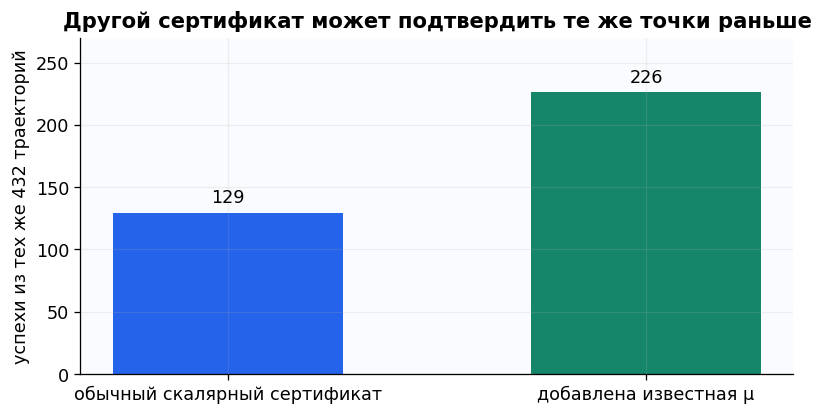

In [18]:
if project_root is not None:
    monitors = read_csv('Work/certificate_results/summary.csv')
    profiles = ['scalar','known_mu']
    successes = [sum(r['certified']=='True' for r in monitors if r['profile']==p) for p in profiles]
    assert [sum(r['profile']==p for r in monitors) for p in profiles] == [432,432]
    assert successes==[129,226]
    fig, ax = plt.subplots(figsize=(8,3.8))
    bars = ax.bar(['обычный скалярный сертификат','добавлена известная μ'],successes,
                  color=[BLUE,GREEN],width=.55)
    ax.bar_label(bars,padding=4)
    ax.set(ylim=(0,270),ylabel='успехи из тех же 432 траекторий',
           title='Другой сертификат может подтвердить те же точки раньше')
    plt.show()

Точки алгоритма не стали лучше от этой проверки: изменилось то,
что мы можем о них **достоверно заключить**. Дополнительная информация
о $\mu$ получена извне; это не адаптация к неизвестной сильной выпуклости.

Другие контроли статьи тоже важны:

- Разделяли влияние новой формулы шагов и обязательной смены старта
  на вершину. Улучшение нельзя автоматически приписать шагу,
  если одновременно изменился старт.
- Проверяли радиус и масштаб единиц функции. Умножение потерь
  на число меняет численные параметры и может менять поведение
  ненормированной инициализации.
- Усредняли касательные блоками и оплачивали дополнительные LMO.
  Проверенные размеры блоков не дали более ранней остановки.
- Сохраняли неудачи и отдельно считали функцию, градиент, полный LMO
  и просмотр активного множества. У этих операций разная стоимость;
  универсальный пересчёт их в одно «время» здесь не вводился.

Вычисленный отдельно эталон нужен для анализа фактической ошибки.
Он не передавался решателям. Численный эталон — не точное знание
оптимума и не формальный интервальный сертификат.

## 16. Можно подвигать итерации самостоятельно

> **Обозначения под рукой.** $k$ — номер выбранной точки; $x_k$ — текущая точка; $s_k$ — ответ линейного оракула LMO.
> $\delta_k=f(x_k)-f_Q^*$ — истинная ошибка, известная нам только для проверки учебного примера.
> $G_k$ — FW-зазор сейчас; $U_k=f(x_k)-\ell_k$ — сертификат с памятью; $\delta_k\le U_k\le G_k$.
> $M$ — начальная настройка кривизны; `eps` — допуск остановки; начальные веса задают стартовую смесь вершин.

В живом Jupyter следующий ползунок показывает текущую точку обычного
FW из пункта 5. Выберите номер и нажмите «Показать выбранный шаг».
Круг — текущая точка, оранжевая стрелка — к LMO-вершине,
синяя точка — результат принятого шага. Справа — истинная ошибка,
сертификат с памятью и FW-зазор в выбранный момент.

В статическом просмотре ползунок может не работать; предыдущие
картинки и таблицы полностью передают пример. Для экспериментов
также можно раскрыть код и поменять M, начальные веса или eps.

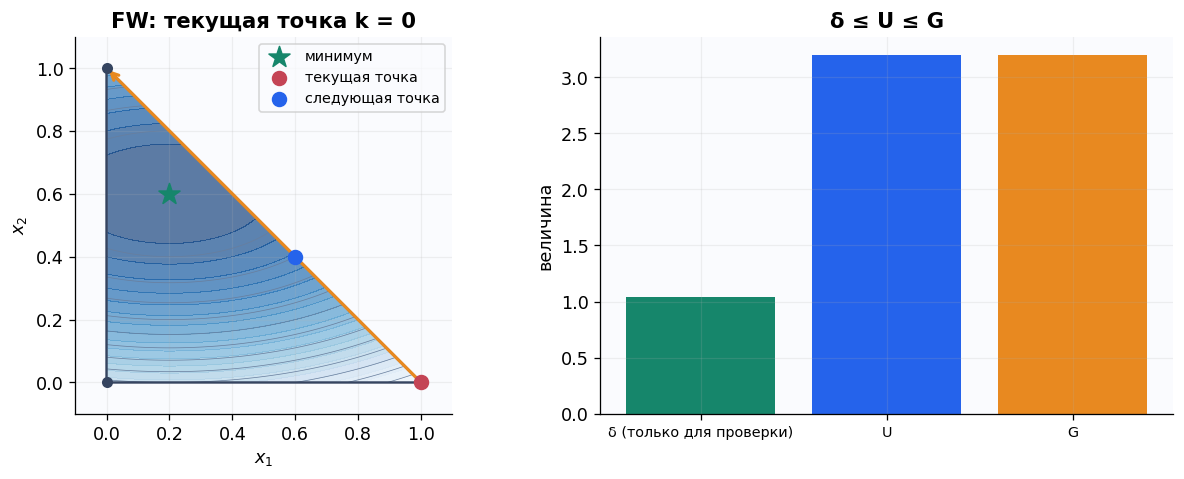

In [19]:
def show_iteration(k=0):
    r = triangle_run[k]
    x = r['x']
    s = V[np.argmin(V@bowl_grad(x))]
    fig, axes = plt.subplots(1,2,figsize=(11,4.3))
    draw_triangle(axes[0])
    axes[0].scatter(*x,s=75,color=RED,zorder=7,label='текущая точка')
    axes[0].annotate('',s,x,arrowprops={'arrowstyle':'->','color':ORANGE,'lw':2})
    if k+1<len(triangle_run):
        axes[0].scatter(*triangle_run[k+1]['x'],s=75,color=BLUE,zorder=7,label='следующая точка')
    axes[0].set_title(f'FW: текущая точка k = {k}')
    axes[0].legend(fontsize=9)
    axes[1].bar(['δ (только для проверки)','U','G'],[r['f'],r['U'],r['G']],
                 color=[GREEN,BLUE,ORANGE])
    axes[1].set(ylabel='величина',title='δ ≤ U ≤ G')
    axes[1].tick_params(axis='x',labelsize=9)
    plt.tight_layout(); plt.show()

# A static initial state is always visible; widgets are an optional enhancement.
show_iteration(0)
try:
    import ipywidgets as widgets
except ImportError:
    print('Для ползунка можно установить ipywidgets; статические рисунки уже доступны.')
else:
    slider = widgets.IntSlider(value=0,min=0,max=len(triangle_run)-1,description='шаг k:',
                               continuous_update=False,layout=widgets.Layout(width='70%'))
    button = widgets.Button(description='Показать выбранный шаг',layout=widgets.Layout(width='230px'))
    widget_output = widgets.Output()
    def redraw(_):
        with widget_output:
            widget_output.clear_output(wait=True)
            show_iteration(slider.value)
    button.on_click(redraw)
    display(widgets.VBox([slider,button,widget_output]))

## 17. Что осталось в приложениях и как это связано с рассказом

> **Обозначения под рукой.** $\delta=f-f^*$ — истинная ошибка; $G$ — FW-зазор; $U=f-\ell$ — сертификат; $E$ — верхняя граница $G$ через $\delta$.
> $H_0,H_1$ — параметры ограничения кривизны; $D$ — диаметр области; $\kappa$ — дополнительная константа геометрического продвижения.
> $\widehat f,\widehat g$ — неточные значение функции и градиент; $\nu,\eta,\zeta$ — границы ошибок функции, градиента и LMO соответственно.
> Здесь $\eta$ — ошибка градиента; не путайте её с $\eta_\varepsilon$, порогом истинной ошибки в пункте 13.

| Тема приложения | Смысл без специальной подготовки |
| --- | --- |
| Шаги сравнения и нормировка | Если параметры известны, можно явно выбрать безопасный шаг. Это информированный контроль, а не основной BT-алгоритм. Точная минимизация по отрезку — более сильная подзадача; её внутренние вычисления не бесплатны. |
| Геометрические следствия | Обосновываются условия на κ: свойства функции плюс форма многогранника превращают ошибку в достаточно сильный сигнал направления. |
| Достигающие примеры | Строятся функции, где граница E(δ) достигается: верхнюю кривую нельзя просто уменьшить для всего класса. |
| Глобальная градиентная оценка | Для выпуклой задачи на всём пространстве с достигнутым минимумом выводится ‖∇f‖² ≤ 2H₀δ + H₁δ². Это отдельные условия! На границе компакта такое неравенство вообще может быть неверно. |
| Другие нижние границы | Исследуется, как усилить сертификат, не меняя сам путь оптимизации, и сколько стоят дополнительные обращения к LMO. |
| Ошибки оракулов | Если функция, градиент и LMO неточны, касательную границу нужно ослабить на величину известных ошибок. Иначе остановка может оказаться ложной. |
| Протокол и контроли | Указано, как построены задачи, старты, бюджеты и численные эталоны, чтобы сравнение можно было воспроизвести. |
| Сравнение с литературой | Отделены известные алгоритмы и сертификаты от специальных оценок этой статьи. |
| Проверки свидетельств | Хеши, тесты и конечные точные аудиты помогают находить ошибки, но не заменяют математическое доказательство и независимую рецензию. |

Например, у $f(x)=x$ на $[0,1]$ в оптимуме $\delta=0$, но
градиент равен 1. Поэтому глобальную оценку из строки таблицы нельзя
без изменения предположений переносить на условный минимум.

Если известны детерминированные ошибки
$|\widehat f-f(x)|\le\nu$,
$\|\widehat g-\nabla f(x)\|\le\eta$, а LMO для $\widehat g$
ошибается по линейной цели не больше чем на $\zeta$, то корректна
нижняя граница

$$\widehat f+\langle\widehat g,s-x\rangle
-\nu-\eta D-\zeta\le f_Q^*.$$

Не вычесть эти поправки — значит иногда «доказать» несуществующую
точность. Это поправка сертификата, а не автоматическое сохранение
всех точных оценок сложности при шуме.

### Отдельная папка `some md research` — другая задача

Она исследует информационные нижние границы для безусловной
оптимизации: сколько запросов **любой** метод вынужден сделать.
Основная статья в этом ноутбуке — о верхних гарантиях конкретных
FW/AFW на ограниченной области. Это разные вопросы и модели.
Общая нижняя граница для H₁ в заметках остаётся открытой;
графики этого ноутбука её не доказывают.

### Короткий словарь

| Запись / слово | Перевод |
| --- | --- |
| k, N | Текущий номер; общее число принятых обновлений |
| f, Q, x* | Цена; разрешённая область; любой минимум на ней |
| δ = f − f* | Истинная ошибка, обычно неизвестная алгоритму |
| ∇f, ∇²f | Градиент — наклон; гессиан — матрица изменений наклона |
| LMO, s | Линейная подзадача; выбранная разрешённая точка |
| d, α | Направление шага; его длина в единицах направления |
| G | Полный FW-зазор, вычислимый сейчас |
| ℓ, U | Лучшая накопленная нижняя граница; текущий сертификат f − ℓ |
| ε | Требуемая точность, условие остановки U ≤ ε |
| H₀, H₁ | Константы предположения о кривизне, не вход основного BT |
| L, M | Рабочая кривизна для пробы; её начальная настройка |
| D | Диаметр области, не расстояние от старта до минимума |
| J, P | Число двоичных уровней точности; цена инициализации |
| атом, S, λ | Вершина в смеси; активные атомы; их веса |
| грань | Край многогранника; в 2D — ребро, вершина или всё множество |
| m, τ в теореме точной остановки | Запас отделения плохих атомов; порог входа в область удаления |
| κ | Дополнительная константа, связывающая направление с ошибкой |
| E, η_ε | Верхняя граница G через δ; достаточный порог истинной ошибки |
| O(·), Θ(·) | Порядок верхней оценки; совпадающий порядок сверху и снизу при оговорённом пределе |

Не путайте $m$ — размер выборки в экспериментах, число хороших шагов
в подсчёте AFW и запас атомов в теореме точной остановки.
Одна буква переиспользуется в разных разделах, смысл задаёт контекст.

## 18. Как теперь читать саму статью

> **Обозначения под рукой.** $\delta_k$ — неизвестная истинная ошибка; $G_k$ — FW-зазор; $\ell_k$ — сохранённая нижняя граница минимума; $U_k=f(x_k)-\ell_k$ — сертификат.
> $\varepsilon$ — требуемая точность: $U_k\le\varepsilon$ подтверждает $\delta_k\le\varepsilon$.
> $M$ — начальная настройка; $L$ — подбираемая кривизна; $H_0,H_1$ — параметры теоретического ограничения кривизны, не вход основного BT.
> FW идёт к выбранной LMO-точке; AFW также умеет уменьшать вес плохого активного атома.

1. Во введении ищите конкретный вопрос: стоимость **проверяемой**
   остановки, а не создание FW заново.
2. В разделе про backtracking найдите четыре вещи:
   ограничение гессиана, определения G/ℓ/U, правило шага и оценку N.
3. В разделе AFW смотрите на веса атомов и подсчёт удалений.
   Затем — на разницу между истинной ошибкой и наблюдаемым порогом.
4. В разделе H₀ = 0 сначала поймите геометрический вывод:
   вся выделенная грань — множество решений. Потом читайте
   доказательство конечного удаления плохих атомов.
5. В экспериментах всегда проверяйте три подписи:
   **какой бюджет**, **какой сертификат**, **что знает алгоритм**.
   Только после этого сравнивайте числа.
6. В приложениях ищите детали нужного вывода, а не читайте все
   технические оценки подряд с первой попытки.

### Самопроверка: семь вопросов

Попробуйте сначала ответить сами, потом раскройте ответы.

1. Если алгоритм выбрал вершину, значит ли это, что минимум там?
2. Если U = 0.01, знаем ли мы точную ошибку?
3. Нужно ли знать H₀,H₁, чтобы запустить основной backtracking?
4. Означают ли 100 шагов ровно 100 вызовов функции?
5. Чем «линейная сходимость» отличается от конечной точной остановки?
6. Можно ли перенести конечную остановку при H₀ = 0 на любое маленькое H₀ > 0?
7. Доказывает ли точность огибающей E оптимальность алгоритма по числу запросов?

<details>
<summary><b>Ответы</b></summary>

1. Нет. Это минимум линейной модели, а не обязательно самой функции.
2. Нет. При корректном сертификате ошибка лежит между 0 и 0.01.
3. Нет. Они нужны для теоретического анализа. Рабочее L подбирается пробами.
4. Нет. Отказы тоже вызывают функцию; есть начальная и финальная проверки.
5. Геометрическая скорость означает быстрое приближение; ни одна конечная
   точка при этом не обязана быть точным минимумом.
6. Нет. Квадратичный контрпример остаётся неточным на каждом конечном шаге.
7. Нет. Это разные утверждения: о поточечном неравенстве и о трудности задачи.

</details>

### Рассказ о статье в пяти фразах

Мы берём известный Франк–Вульф с подбором шага и известным
вычислимым сертификатом остановки. Предполагаем, что разрешённая
кривизна зависит от ошибки функции. Доказываем более информативную
верхнюю оценку работы, учитывающую настройку и неудачные пробы.
Выводим точную связь FW-зазора с истинной ошибкой. В особом случае
H₀ = 0 на многограннике показываем, почему AFW конечным удалением
атомов может решить задачу **точно**, и проверяем практические
вопросы инициализации, геометрии и остановки на сохранённых экспериментах.

Что здесь не заявляется: новый общий алгоритм FW, универсальная
победа по времени, нижняя оценка сложности всех методов или
подтверждённое абсолютное первенство. Проверка литературы и
математическая рецензия — отдельная работа.

Собственные формулы и графики можно менять, но при изменении функции
параметры H₀,H₁ и все дополнительные условия нужно проверять заново.

In [20]:
# Internal consistency checks for the demonstrations, not new research claims.
for trace in [triangle_run,paid_run,edge_fw,edge_afw,zero_run,*linear_runs]:
    assert all(r['U']<=r['G']+1e-9 for r in trace)
    assert all(abs(r['weights'].sum()-1)<1e-12 for r in trace)
    assert all(np.min(r['weights'])>=0 for r in trace)
    assert all(trace[i+1]['f']<=trace[i]['f']+1e-11 for i in range(len(trace)-1))
    assert all(trace[i+1]['U']<=trace[i]['U']+1e-10 for i in range(len(trace)-1))
    assert trace[-1]['ng']==trace[-1]['nlmo']==len(trace)
    assert trace[-1]['nf']==1+sum(len(r.get('trials',[])) for r in trace)
assert zero_run[-1]['U']==0
assert all(p>0 for p in exact_points)
print('Проверены: допустимость точек, убывание функции и U, U ≤ G, '
      'счётчики проб, пример точного удаления, квадратичный контрпример '
      'и числа из сохранённых таблиц. Учебный ноутбук выполнен до конца.')

Проверены: допустимость точек, убывание функции и U, U ≤ G, счётчики проб, пример точного удаления, квадратичный контрпример и числа из сохранённых таблиц. Учебный ноутбук выполнен до конца.
